# 04 — Results tables (descriptive)

Test-set results of every model at 100 % of the labels and across label fractions, as mean ± SD over the training
seeds. No statistical test here (see `03_statistics.ipynb`).

| | Ulcer | MES, LIMUC |
|---|---|---|
| Overall AUROC | P(ulcer); frame and clip | macro one-vs-rest over Mayo 0–3; frame and clip (LIMUC: one image per clip) |
| Operating point (set before testing) | threshold maximising validation F1, per seed; fixed 0.5 for comparison | argmax grade; active disease = argmax ≥ 2 |
| Clinical endpoint | sensitivity / specificity at that threshold | active disease (Mayo 2–3) vs remission (Mayo 0–1): AUROC of p2 + p3, sensitivity / specificity |
| Agreement | MCC at that threshold | quadratic weighted kappa (QWK) of the argmax grade |
| Per grade | — | recall of each Mayo grade |

Figures put the CNNs (ResNet-50, EfficientNet-B0), the ViTs (ViT-S/16, ViT-S/14) and, once they have results, the
exploratory ViT-B models (336 px) side by side. Section 9: the external test (MES runs of each site on the other site's
test split). Reads the committed `results/` tables; the ulcer metrics at 0.5 and the confusion matrices need the
local test predictions.

In [2]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path("..")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analysis.catalog import (  # noqa: E402
    COLORS,
    ENDPOINT_METRIC,
    FAMILY_ORDER,
    FULL_PCT,
    MES_CLASS_NAMES,
    MODEL_ORDER,
    RESULTS,
    RESULTS_VITB,
    SECONDARY_MODELS,
    ULCER_CLASS_NAMES,
    model_family,
    model_label,
    pm,
    predictions_dir,
    read_meta,
)
from src.analysis.figures import (  # noqa: E402
    curve_axes,
    draw_curve,
    draw_mean_cm,
    model_style,
    x_ticks,
    y_limits,
)
from src.analysis.predictions import seed_confusions  # noqa: E402
from src.utils.results import aggregate_seed_results, binary_metrics_at_threshold  # noqa: E402

%matplotlib inline
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # no paths
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 40)

## 1. Runs and test splits

Fine-tuned runs with a linear head. Planned models without results are listed and left out of every table.

In [3]:
DATASETS = {"ulcer": "Ulcer", "mes": "MES", "limuc": "LIMUC"}
AGG_TASK = {"ulcer": "ulcer", "mes": "mes", "limuc": "mes"}  # metric set of aggregate_seed_results
MODELS = [*MODEL_ORDER, *SECONDARY_MODELS]  # the main models, then the exploratory ViT-B models
ORDER = {m: i for i, m in enumerate(MODELS)}
FAMILIES = {f: [m for m in MODELS if model_family(m) == f] for f in FAMILY_ORDER}  # CNN, ViT, ViT-B


def by_model(df: pd.DataFrame, *cols: str) -> pd.DataFrame:
    """Rows in MODEL_ORDER, then by `cols`."""
    key = lambda s: s.map(ORDER) if s.name == "model" else s  # noqa: E731
    return df.sort_values(["model", *cols], key=key).reset_index(drop=True)


def load_runs(ds: str) -> pd.DataFrame:
    """Per-seed rows of the planned models present: the main runs, then the ViT-B runs once finished."""
    df = pd.concat([pd.read_csv(f / "results_per_seed.csv") for f in (RESULTS[ds], RESULTS_VITB[ds])
                    if (f / "results_per_seed.csv").is_file()], ignore_index=True)
    df = df[(df["freeze"] == "finetune") & (df["head_type"] == "linear")]
    present = [m for m in MODELS if m in set(df["model"])]
    seeds = df.groupby(["model", "pct_data"])["seed"].nunique()
    n_seeds = f"{seeds.min()}" if seeds.min() == seeds.max() else f"{seeds.min()}–{seeds.max()}"
    print(f"{DATASETS[ds]}: {len(df)} runs = {len(present)} models × {df['pct_data'].nunique()} fractions × "
          f"{n_seeds} seeds")
    if absent := [model_label(m) for m in MODELS if m not in present]:
        print("  no results yet:", "; ".join(absent))
    if other := sorted(set(df["model"]) - set(MODELS)):
        print("  not in MODELS, left out:", ", ".join(other))
    return by_model(df[df["model"].isin(present)], "pct_data", "seed")


def test_split(ds: str) -> dict:
    """Test-split counts recorded by the runner (experiment_meta.json); {} when absent."""
    s = read_meta(ds).get("split_summary") or {}
    if not s:
        return {}
    per_class = {int(k): v["test"] for k, v in sorted(s["per_class"].items(), key=lambda kv: int(kv[0]))}
    return {"frames": s["n_frames"]["test"], "clips": s["n_clips"]["test"], "patients": s["n_patients"]["test"],
            "per_class": {k: int(v["frames"]) for k, v in per_class.items()},
            "clips_per_class": {k: int(v["clips"]) for k, v in per_class.items()}}


RUNS = {ds: load_runs(ds) for ds in DATASETS if (RESULTS[ds] / "results_per_seed.csv").is_file()}
FAMILY_ORDER = [f for f in FAMILY_ORDER if any(set(FAMILIES[f]) & set(df["model"]) for df in RUNS.values())]  # panels
AGG = {ds: by_model(aggregate_seed_results(df, AGG_TASK[ds]), "pct_data") for ds, df in RUNS.items()}  # = results.csv
TEST = {ds: test_split(ds) for ds in RUNS}


def pm_table(ds: str, metrics: dict, pct: int | None = FULL_PCT, agg: pd.DataFrame | None = None) -> pd.DataFrame:
    """'mean ± SD' over seeds of results.csv metrics {prefix: header}; rows = models (× fractions if pct is None).
    `agg`: results table read instead of AGG[ds] (external test, Section 9)."""
    agg = AGG[ds] if agg is None else agg
    agg = agg if pct is None else agg[agg["pct_data"] == pct]
    metrics = {c: h for c, h in metrics.items() if f"{c}_mean" in agg}  # e.g. no QWK in older results
    labels = agg["model"].map(model_label).to_numpy()
    index = (pd.Index(labels, name="model") if pct is not None
             else pd.MultiIndex.from_arrays([labels, agg["pct_data"].to_numpy()], names=["model", "nominal %"]))
    return pd.DataFrame({head: [pm(m, s) for m, s in zip(agg[f"{c}_mean"], agg[f"{c}_std"], strict=True)]
                         for c, head in metrics.items()}, index=index)


display(pd.DataFrame({
    DATASETS[ds]: {"frames": t["frames"], "clips": t["clips"], "patients": t["patients"],
                   "frames per class": " / ".join(map(str, t["per_class"].values())),
                   "clips per class": " / ".join(map(str, t["clips_per_class"].values()))}
    for ds, t in TEST.items() if t
}).T.rename_axis("test split"))

Ulcer: 600 runs = 12 models × 5 fractions × 10 seeds
MES: 600 runs = 12 models × 5 fractions × 10 seeds
LIMUC: 840 runs = 12 models × 7 fractions × 10 seeds


,frames,clips,patients,frames per class,clips per class
test split,,,,,
Ulcer,2526,87,19,1592 / 934,46 / 41
MES,5320,91,34,1311 / 1522 / 1864 / 623,42 / 14 / 25 / 10
LIMUC,1522,1522,85,854 / 406 / 163 / 99,854 / 406 / 163 / 99


## 2. Realised training fractions

Subsets are drawn per seed and shared by every model; each grade keeps the nominal fraction of its training frames
(the last clip drawn is cut), so the realised fraction is the nominal one to a frame per grade.
Mean (min–max) over seeds.

In [4]:
def realised(df: pd.DataFrame) -> pd.DataFrame:
    if df.groupby(["pct_data", "seed"])["n_train"].nunique().max() > 1:
        warnings.warn("training subsets differ between models", stacklevel=1)
    g = df.drop_duplicates(["pct_data", "seed"]).groupby("pct_data")
    span = lambda c, f=1: [f"{f * lo:.4g}–{f * hi:.4g}" for lo, hi in zip(g[c].min(), g[c].max(), strict=True)]  # noqa: E731
    return pd.DataFrame({
        "realised %": [f"{m} ({s})" for m, s in zip((100 * g["realized_fraction"].mean()).round(1),
                                                     span("realized_fraction", 100), strict=True)],
        "train frames": span("n_train"), "train clips": span("n_clips"), "train patients": span("n_patients"),
    }, index=pd.Index(list(g.groups), name="nominal %"))


display(pd.concat({DATASETS[ds]: realised(df) for ds, df in RUNS.items()}, axis=1).sort_index().fillna("—"))

Ulcer                                          \
                   realised % train frames train clips train patients   
nominal %                                                               
1                           —            —           —              —   
5                           —            —           —              —   
10         10.0 (10.01–10.01)      274–274        8–12           4–11   
25               25.0 (25–25)      684–684       21–24          10–14   
50               50.0 (50–50)    1368–1368       41–47          14–18   
75               75.0 (75–75)    2052–2052       61–67          16–18   
100           100.0 (100–100)    2736–2736       87–87          18–18   

                          MES                                          \
                   realised % train frames train clips train patients   
nominal %                                                               
1                           —            —           —              —   
5                           —            —           —              —   
10         10.0 (9.998–9.998)      492–492        8–15           6–11   
25         25.0 (24.99–24.99)    1230–1230       17–26          13–18   
50         50.0 (50.01–50.01)    2461–2461       27–42          22–27   
75         75.0 (75.01–75.01)    3691–3691       46–58          28–32   
100           100.0 (100–100)    4921–4921       69–69          33–33   

                        LIMUC                                          
                   realised % train frames train clips train patients  
nominal %                                                              
1                   1.0 (1–1)        82–82       81–82          66–76  
5           5.0 (5.001–5.001)      410–410     408–410        206–225  
10               10.0 (10–10)      820–820     818–820        286–303  
25               25.0 (25–25)    2050–2050   2044–2050        357–367  
50         50.0 (50.01–50.01)    4100–4100   4093–4098        383–390  
75               75.0 (75–75)    6149–6149   6139–6145        390–394  
100           100.0 (100–100)    8199–8199   8189–8189        395–395

## 3. Overall AUROC at 100 % labels

Clip score: mean frame probability of the clip. The MES clip AUROC rests on few test clips (Section 1).

In [5]:
OVERALL = {
    "ulcer": {"auroc": "frame AUROC", "clip_auroc": "clip AUROC"},
    "mes": {"auroc": "frame AUROC", "clip_auroc": "clip AUROC", "macro_f1": "macro-F1", "qwk": "QWK"},
    "limuc": {"auroc": "frame AUROC", "macro_f1": "macro-F1", "qwk": "QWK"},  # one image per clip: no clip metrics
}
display(pd.concat({DATASETS[ds]: pm_table(ds, OVERALL[ds]) for ds in AGG}, axis=1).fillna("—"))

Ulcer                 \
                                           frame AUROC     clip AUROC   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.794 ± 0.013  0.833 ± 0.018   
ResNet-50 / GastroNet-200K (DINOv1)      0.915 ± 0.012  0.920 ± 0.011   
ResNet-50 / GastroNet-1M (DINOv1)        0.936 ± 0.011  0.943 ± 0.008   
ResNet-50 / GastroNet-5M (DINOv1)        0.928 ± 0.010  0.933 ± 0.007   
EfficientNet-B0 / ImageNet (supervised)  0.867 ± 0.020  0.892 ± 0.016   
ViT-S/16 / ImageNet (DINOv1)             0.892 ± 0.016  0.889 ± 0.012   
ViT-S/16 / GastroNet-5M (DINOv1)         0.955 ± 0.008  0.956 ± 0.011   
ViT-S/14 / LVD-142M (DINOv2)             0.928 ± 0.007  0.917 ± 0.007   
ViT-S/16 / LVD-1689M (DINOv3)            0.904 ± 0.017  0.918 ± 0.009   
ViT-B/14 / LVD-142M (DINOv2)             0.952 ± 0.003  0.950 ± 0.007   
ViT-B/14 / GastroNet-5M (DINOv2)         0.981 ± 0.003  0.979 ± 0.003   
ViT-B/16 / LVD-1689M (DINOv3)            0.900 ± 0.022  0.913 ± 0.016   

                                                   MES                 \
                                           frame AUROC     clip AUROC   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.654 ± 0.006  0.758 ± 0.005   
ResNet-50 / GastroNet-200K (DINOv1)      0.653 ± 0.010  0.778 ± 0.009   
ResNet-50 / GastroNet-1M (DINOv1)        0.655 ± 0.010  0.794 ± 0.009   
ResNet-50 / GastroNet-5M (DINOv1)        0.680 ± 0.016  0.808 ± 0.011   
EfficientNet-B0 / ImageNet (supervised)  0.662 ± 0.008  0.764 ± 0.007   
ViT-S/16 / ImageNet (DINOv1)             0.636 ± 0.012  0.762 ± 0.014   
ViT-S/16 / GastroNet-5M (DINOv1)         0.672 ± 0.016  0.785 ± 0.012   
ViT-S/14 / LVD-142M (DINOv2)             0.660 ± 0.010  0.767 ± 0.011   
ViT-S/16 / LVD-1689M (DINOv3)            0.673 ± 0.010  0.784 ± 0.008   
ViT-B/14 / LVD-142M (DINOv2)             0.702 ± 0.006  0.790 ± 0.008   
ViT-B/14 / GastroNet-5M (DINOv2)         0.687 ± 0.011  0.778 ± 0.009   
ViT-B/16 / LVD-1689M (DINOv3)            0.665 ± 0.016  0.757 ± 0.012   

                                                                       \
                                              macro-F1            QWK   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.281 ± 0.006  0.350 ± 0.013   
ResNet-50 / GastroNet-200K (DINOv1)      0.283 ± 0.011  0.387 ± 0.031   
ResNet-50 / GastroNet-1M (DINOv1)        0.277 ± 0.009  0.392 ± 0.030   
ResNet-50 / GastroNet-5M (DINOv1)        0.307 ± 0.017  0.448 ± 0.027   
EfficientNet-B0 / ImageNet (supervised)  0.301 ± 0.007  0.378 ± 0.013   
ViT-S/16 / ImageNet (DINOv1)             0.280 ± 0.015  0.346 ± 0.030   
ViT-S/16 / GastroNet-5M (DINOv1)         0.294 ± 0.029  0.432 ± 0.020   
ViT-S/14 / LVD-142M (DINOv2)             0.299 ± 0.009  0.377 ± 0.018   
ViT-S/16 / LVD-1689M (DINOv3)            0.303 ± 0.009  0.422 ± 0.010   
ViT-B/14 / LVD-142M (DINOv2)             0.327 ± 0.016  0.400 ± 0.015   
ViT-B/14 / GastroNet-5M (DINOv2)         0.307 ± 0.015  0.496 ± 0.026   
ViT-B/16 / LVD-1689M (DINOv3)            0.286 ± 0.010  0.382 ± 0.022   

                                                 LIMUC                 \
                                           frame AUROC       macro-F1   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.930 ± 0.002  0.700 ± 0.005   
ResNet-50 / GastroNet-200K (DINOv1)      0.935 ± 0.002  0.709 ± 0.013   
ResNet-50 / GastroNet-1M (DINOv1)        0.935 ± 0.003  0.714 ± 0.013   
ResNet-50 / GastroNet-5M (DINOv1)        0.937 ± 0.001  0.721 ± 0.011   
EfficientNet-B0 / ImageNet (supervised)  0.928 ± 0.002  0.701 ± 0.009   
ViT-S/16 / ImageNet (DINOv1)             0.934 ± 0.002  0.694 ± 0.013   
ViT-S/16 / GastroNet-5M (DINOv1)         0.942 ± 0.002  0.722 ± 0.028   
ViT-S/14 / LVD-142M (DINOv2)   

## 4. Operating points at 100 % labels

Ulcer: per-seed validation-F1 threshold vs the fixed 0.5. MES / LIMUC: active disease at argmax ≥ 2 (nothing tuned),
with the AUROC of p2 + p3.

In [6]:
u = RUNS["ulcer"][RUNS["ulcer"]["pct_data"] == FULL_PCT]


def at_half(model: str) -> pd.DataFrame | None:
    """Ulcer metrics at 0.5 of every seed, from the saved test predictions (local only); None when absent."""
    rows = []
    for _, r in u[u["model"] == model].iterrows():
        d = predictions_dir("ulcer", model, int(r["seed"]))
        if not (d / "test_probs.npy").is_file():
            return None
        m = binary_metrics_at_threshold(np.load(d / "test_labels.npy"), np.load(d / "test_probs.npy").squeeze(), 0.5)
        if not np.isclose(m["f1"], r["f1"]):
            raise AssertionError(f"{r['run_name']}: predictions disagree with results_per_seed.csv")
        rows.append({k: m[k] for k in ("sensitivity", "specificity")})
    return pd.DataFrame(rows)


tuned = pm_table("ulcer", {"tuned_sensitivity": "sensitivity", "tuned_specificity": "specificity", "tuned_f1": "F1",
                          "tuned_mcc": "MCC"})
thr = u.groupby(u["model"].map(model_label), sort=False)["tuned_threshold"]
tuned.insert(0, "threshold (min–max)", [f"{m:.3g} ({lo:.2g}–{hi:.2g})" for m, lo, hi
                                         in zip(thr.mean()[tuned.index], thr.min()[tuned.index],
                                                thr.max()[tuned.index], strict=True)])
fixed = pm_table("ulcer", {"f1": "F1"})
half = {model_label(m): at_half(m) for m in u["model"].unique()}
if all(h is not None for h in half.values()):
    for i, col in enumerate(("sensitivity", "specificity")):
        fixed.insert(i, col, [pm(half[k][col].mean(), half[k][col].std()) for k in fixed.index])
else:
    print("Sensitivity / specificity at 0.5 need the saved test predictions (local only).")
print(f"Ulcer at {FULL_PCT} %; thresholds at the edge of the validation search grid: "
      f"{int(u['tuned_threshold_at_edge'].eq(True).sum())} of {len(u)} runs")
display(pd.concat({"validation-F1 threshold (per seed)": tuned, "fixed 0.5": fixed}, axis=1))

Ulcer at 100 %; thresholds at the edge of the validation search grid: 0 of 120 runs


validation-F1 threshold (per seed)  \
                                                       threshold (min–max)   
model                                                                        
ResNet-50 / ImageNet (DINOv1)                            0.483 (0.44–0.51)   
ResNet-50 / GastroNet-200K (DINOv1)                      0.725 (0.32–0.98)   
ResNet-50 / GastroNet-1M (DINOv1)                       0.437 (0.042–0.85)   
ResNet-50 / GastroNet-5M (DINOv1)                           0.691 (0.25–1)   
EfficientNet-B0 / ImageNet (supervised)                  0.471 (0.39–0.54)   
ViT-S/16 / ImageNet (DINOv1)                          0.288 (2.4e-06–0.84)   
ViT-S/16 / GastroNet-5M (DINOv1)                       0.34 (1.2e-07–0.99)   
ViT-S/14 / LVD-142M (DINOv2)                          0.173 (0.00035–0.87)   
ViT-S/16 / LVD-1689M (DINOv3)                            0.262 (0.063–0.6)   
ViT-B/14 / LVD-142M (DINOv2)                               0.549 (0.013–1)   
ViT-B/14 / GastroNet-5M (DINOv2)                       0.149 (0.0043–0.45)   
ViT-B/16 / LVD-1689M (DINOv3)                            0.614 (0.41–0.82)   

                                                                       \
                                           sensitivity    specificity   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.760 ± 0.037  0.672 ± 0.039   
ResNet-50 / GastroNet-200K (DINOv1)      0.703 ± 0.092  0.916 ± 0.050   
ResNet-50 / GastroNet-1M (DINOv1)        0.843 ± 0.073  0.884 ± 0.054   
ResNet-50 / GastroNet-5M (DINOv1)        0.696 ± 0.101  0.914 ± 0.058   
EfficientNet-B0 / ImageNet (supervised)  0.741 ± 0.049  0.850 ± 0.036   
ViT-S/16 / ImageNet (DINOv1)             0.760 ± 0.086  0.853 ± 0.054   
ViT-S/16 / GastroNet-5M (DINOv1)         0.837 ± 0.066  0.922 ± 0.054   
ViT-S/14 / LVD-142M (DINOv2)             0.826 ± 0.024  0.860 ± 0.025   
ViT-S/16 / LVD-1689M (DINOv3)            0.826 ± 0.036  0.809 ± 0.035   
ViT-B/14 / LVD-142M (DINOv2)             0.826 ± 0.034  0.916 ± 0.024   
ViT-B/14 / GastroNet-5M (DINOv2)         0.917 ± 0.031  0.954 ± 0.019   
ViT-B/16 / LVD-1689M (DINOv3)            0.767 ± 0.039  0.856 ± 0.030   

                                                                       \
                                                    F1            MCC   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.656 ± 0.013  0.419 ± 0.024   
ResNet-50 / GastroNet-200K (DINOv1)      0.759 ± 0.037  0.650 ± 0.041   
ResNet-50 / GastroNet-1M (DINOv1)        0.826 ± 0.036  0.726 ± 0.053   
ResNet-50 / GastroNet-5M (DINOv1)        0.753 ± 0.038  0.643 ± 0.033   
EfficientNet-B0 / ImageNet (supervised)  0.742 ± 0.035  0.593 ± 0.056   
ViT-S/16 / ImageNet (DINOv1)             0.755 ± 0.035  0.616 ± 0.044   
ViT-S/16 / GastroNet-5M (DINOv1)         0.849 ± 0.024  0.769 ± 0.039   
ViT-S/14 / LVD-142M (DINOv2)             0.800 ± 0.006  0.678 ± 0.013   
ViT-S/16 / LVD-1689M (DINOv3)            0.768 ± 0.023  0.620 ± 0.040   
ViT-B/14 / LVD-142M (DINOv2)             0.839 ± 0.012  0.748 ± 0.017   
ViT-B/14 / GastroNet-5M (DINOv2)         0.919 ± 0.006  0.872 ± 0.009   
ViT-B/16 / LVD-1689M (DINOv3)            0.762 ± 0.025  0.623 ± 0.040   

                                             fixed 0.5                 \
                                           sensitivity    specificity   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.717 ± 0.084  0.706 ± 0.085   
ResNet-50 / GastroNet-200K (DINOv1)      0.785 ± 0.051  0.877 ± 0.033   
ResNet-50 / GastroNet-1M (DINOv1)        0.818 ± 0.044  0.907 ± 0.031   
ResNet-50 / GastroNet-5M (DINOv1)        0.768 ± 0.044  0.901 ± 0.022   
EfficientNet-B0 / ImageNet (supervised)  0.730 ± 0.034  0.861 ± 0.042   
ViT-S/16 / ImageNet (DINOv1)             0.705 ± 0.058  0.899 ± 0.016   
ViT-S/16 / GastroNet

In [7]:
ACTIVE = {"clin_auroc": "AUROC (p2 + p3)", "clin_sens": "sensitivity", "clin_spec": "specificity", "clin_f1": "F1"}
GRADE_DS = [ds for ds in ("mes", "limuc") if ds in AGG]
print(f"Active disease (Mayo 2–3) vs remission (Mayo 0–1) at {FULL_PCT} %, argmax ≥ 2")
display(pd.concat({DATASETS[ds]: pm_table(ds, ACTIVE) for ds in GRADE_DS}, axis=1))

Active disease (Mayo 2–3) vs remission (Mayo 0–1) at 100 %, argmax ≥ 2


MES                 \
                                        AUROC (p2 + p3)    sensitivity   
model                                                                    
ResNet-50 / ImageNet (DINOv1)             0.775 ± 0.008  0.458 ± 0.028   
ResNet-50 / GastroNet-200K (DINOv1)       0.755 ± 0.019  0.440 ± 0.027   
ResNet-50 / GastroNet-1M (DINOv1)         0.754 ± 0.010  0.453 ± 0.023   
ResNet-50 / GastroNet-5M (DINOv1)         0.763 ± 0.022  0.479 ± 0.023   
EfficientNet-B0 / ImageNet (supervised)   0.779 ± 0.014  0.448 ± 0.023   
ViT-S/16 / ImageNet (DINOv1)              0.756 ± 0.012  0.451 ± 0.069   
ViT-S/16 / GastroNet-5M (DINOv1)          0.797 ± 0.019  0.505 ± 0.041   
ViT-S/14 / LVD-142M (DINOv2)              0.786 ± 0.010  0.459 ± 0.038   
ViT-S/16 / LVD-1689M (DINOv3)             0.774 ± 0.007  0.510 ± 0.016   
ViT-B/14 / LVD-142M (DINOv2)              0.794 ± 0.008  0.505 ± 0.031   
ViT-B/14 / GastroNet-5M (DINOv2)          0.831 ± 0.014  0.614 ± 0.050   
ViT-B/16 / LVD-1689M (DINOv3)             0.751 ± 0.013  0.494 ± 0.026   

                                                                       \
                                           specificity             F1   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.916 ± 0.016  0.589 ± 0.020   
ResNet-50 / GastroNet-200K (DINOv1)      0.938 ± 0.015  0.582 ± 0.023   
ResNet-50 / GastroNet-1M (DINOv1)        0.937 ± 0.016  0.594 ± 0.019   
ResNet-50 / GastroNet-5M (DINOv1)        0.951 ± 0.014  0.624 ± 0.017   
EfficientNet-B0 / ImageNet (supervised)  0.921 ± 0.011  0.582 ± 0.019   
ViT-S/16 / ImageNet (DINOv1)             0.906 ± 0.041  0.576 ± 0.044   
ViT-S/16 / GastroNet-5M (DINOv1)         0.936 ± 0.025  0.639 ± 0.027   
ViT-S/14 / LVD-142M (DINOv2)             0.933 ± 0.014  0.597 ± 0.029   
ViT-S/16 / LVD-1689M (DINOv3)            0.905 ± 0.010  0.631 ± 0.012   
ViT-B/14 / LVD-142M (DINOv2)             0.914 ± 0.022  0.630 ± 0.018   
ViT-B/14 / GastroNet-5M (DINOv2)         0.888 ± 0.040  0.704 ± 0.024   
ViT-B/16 / LVD-1689M (DINOv3)            0.891 ± 0.027  0.610 ± 0.014   

                                                  LIMUC                 \
                                        AUROC (p2 + p3)    sensitivity   
model                                                                    
ResNet-50 / ImageNet (DINOv1)             0.979 ± 0.001  0.850 ± 0.012   
ResNet-50 / GastroNet-200K (DINOv1)       0.980 ± 0.001  0.861 ± 0.018   
ResNet-50 / GastroNet-1M (DINOv1)         0.980 ± 0.001  0.861 ± 0.012   
ResNet-50 / GastroNet-5M (DINOv1)         0.982 ± 0.001  0.876 ± 0.014   
EfficientNet-B0 / ImageNet (supervised)   0.979 ± 0.001  0.866 ± 0.016   
ViT-S/16 / ImageNet (DINOv1)              0.981 ± 0.001  0.840 ± 0.041   
ViT-S/16 / GastroNet-5M (DINOv1)          0.983 ± 0.001  0.869 ± 0.040   
ViT-S/14 / LVD-142M (DINOv2)              0.984 ± 0.001  0.867 ± 0.023   
ViT-S/16 / LVD-1689M (DINOv3)             0.983 ± 0.000  0.883 ± 0.006   
ViT-B/14 / LVD-142M (DINOv2)              0.986 ± 0.001  0.873 ± 0.022   
ViT-B/14 / GastroNet-5M (DINOv2)          0.981 ± 0.001  0.848 ± 0.019   
ViT-B/16 / LVD-1689M (DINOv3)             0.985 ± 0.001  0.856 ± 0.014   

                                                                       
                                           specificity             F1  
model                                                                  
ResNet-50 / ImageNet (DINOv1)            0.964 ± 0.003  0.841 ± 0.003  
ResNet-50 / GastroNet-200K (DINOv1)      0.959 ± 0.006  0.838 ± 0.007  
ResNet-50 / GastroNet-1M (DINOv1)        0.962 ± 0.006  0.843 ± 0.006  
ResNet-50 / GastroNet-5M (DINOv1)        0.962 ± 0.003  0.851 ± 0.007  
EfficientNet-B0 / ImageNet (supervised)  0.955 ± 0.007  0.832 ± 0.009  
ViT-S/16 / ImageNet (DINOv1)             0.966 ± 0.010  0.840 ± 0.007  
ViT-S/16 / GastroNet-5M (DINOv1)         0.965 ± 0.011  0.852 ± 0.013  
ViT-S/14 / LVD

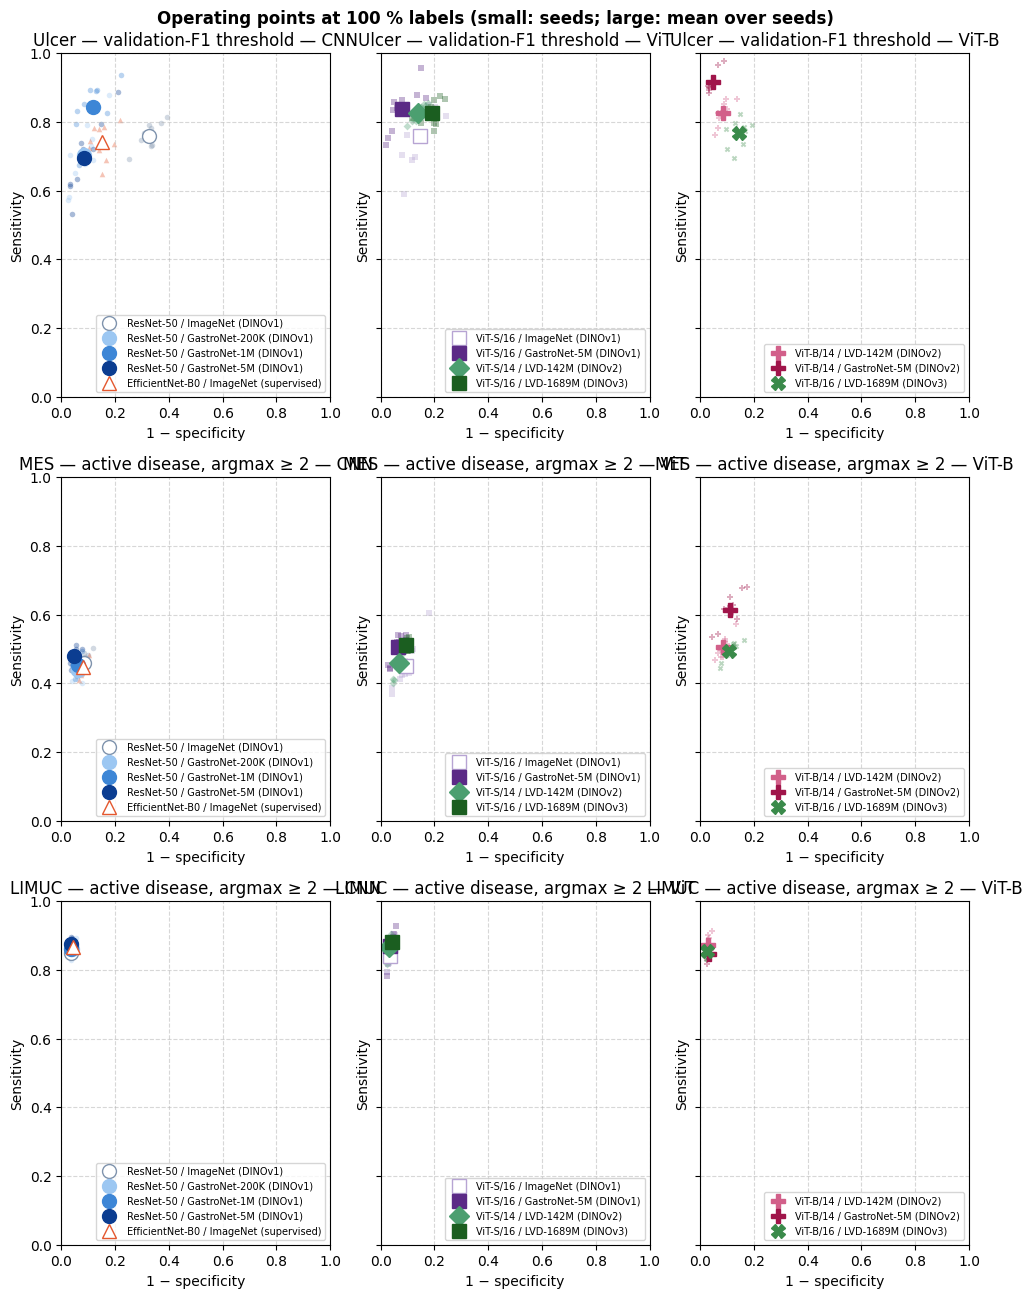

In [8]:
PANELS = {"ulcer": ("tuned_sensitivity", "tuned_specificity", "Ulcer — validation-F1 threshold"),
          "mes": ("clin_sensitivity", "clin_specificity", "MES — active disease, argmax ≥ 2"),
          "limuc": ("clin_sensitivity", "clin_specificity", "LIMUC — active disease, argmax ≥ 2")}
panels = [ds for ds in PANELS if ds in RUNS]
fig, axes = plt.subplots(len(panels), len(FAMILY_ORDER), figsize=(10, 4.4 * len(panels)), squeeze=False,
                         sharex="row", sharey="row")
for row, ds in zip(axes, panels, strict=True):
    sens, spec, title = PANELS[ds]
    sub = RUNS[ds][RUNS[ds]["pct_data"] == FULL_PCT]
    for ax, family in zip(row, FAMILY_ORDER, strict=True):
        for model, g in sub[sub["model"].isin(FAMILIES[family])].groupby("model", sort=False):
            st = {k: v for k, v in model_style(model).items() if k != "linestyle"}
            ax.scatter(1 - g[spec], g[sens], s=16, alpha=0.35, color=st["color"], marker=st["marker"], linewidths=0)
            ax.plot(1 - g[spec].mean(), g[sens].mean(), markersize=10, linestyle="none", label=model_label(model), **st)
        ax.set(title=f"{title} — {family}", xlabel="1 − specificity", ylabel="Sensitivity")
        ax.grid(linestyle="--", alpha=0.5)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.legend(fontsize=7, loc="lower right")
fig.suptitle(f"Operating points at {FULL_PCT} % labels (small: seeds; large: mean over seeds)", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Per-grade recall at 100 % labels

Recall of each Mayo grade (argmax) for every model, then the Mayo 2 recall of GastroNet-5M vs ImageNet within an
architecture (Δ paired by seed: same training subset).

In [9]:
RECALL = {f"sens_mayo{k}": f"Mayo {k}" for k in range(4)}
display(pd.concat({DATASETS[ds]: pm_table(ds, RECALL) for ds in GRADE_DS}, axis=1))

PAIRS = {"ResNet-50": ("resnet50_imagenet", "resnet50_5M"), "ViT-S/16": ("vits16_imagenet", "vits16_gastronet")}
rows = []
for ds in GRADE_DS:
    sub = RUNS[ds][RUNS[ds]["pct_data"] == FULL_PCT].pivot(index="seed", columns="model", values="sens_mayo2")
    for arch, (imagenet, gastronet) in PAIRS.items():
        if {imagenet, gastronet} <= set(sub.columns):
            delta = (sub[gastronet] - sub[imagenet]).dropna()
            rows.append({"dataset": f"{DATASETS[ds]} (n = {TEST[ds]['per_class'][2]})" if TEST[ds] else DATASETS[ds],
                         "architecture": arch,
                         "ImageNet": pm(sub[imagenet].mean(), sub[imagenet].std()),
                         "GastroNet-5M": pm(sub[gastronet].mean(), sub[gastronet].std()),
                         "Δ GastroNet − ImageNet": pm(delta.mean(), delta.std()),
                         "seeds Δ > 0": f"{int((delta > 0).sum())}/{len(delta)}"})
print(f"Mayo 2 recall at {FULL_PCT} % (n = Mayo 2 test frames)")
display(pd.DataFrame(rows).set_index(["dataset", "architecture"]))

MES                 \
                                                Mayo 0         Mayo 1   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.801 ± 0.018  0.161 ± 0.016   
ResNet-50 / GastroNet-200K (DINOv1)      0.849 ± 0.025  0.144 ± 0.031   
ResNet-50 / GastroNet-1M (DINOv1)        0.880 ± 0.029  0.120 ± 0.031   
ResNet-50 / GastroNet-5M (DINOv1)        0.847 ± 0.030  0.189 ± 0.041   
EfficientNet-B0 / ImageNet (supervised)  0.786 ± 0.025  0.207 ± 0.014   
ViT-S/16 / ImageNet (DINOv1)             0.798 ± 0.074  0.164 ± 0.043   
ViT-S/16 / GastroNet-5M (DINOv1)         0.866 ± 0.055  0.178 ± 0.078   
ViT-S/14 / LVD-142M (DINOv2)             0.842 ± 0.059  0.166 ± 0.071   
ViT-S/16 / LVD-1689M (DINOv3)            0.778 ± 0.027  0.205 ± 0.028   
ViT-B/14 / LVD-142M (DINOv2)             0.834 ± 0.042  0.158 ± 0.040   
ViT-B/14 / GastroNet-5M (DINOv2)         0.850 ± 0.051  0.149 ± 0.040   
ViT-B/16 / LVD-1689M (DINOv3)            0.805 ± 0.036  0.138 ± 0.038   

                                                                       \
                                                Mayo 2         Mayo 3   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.232 ± 0.024  0.113 ± 0.019   
ResNet-50 / GastroNet-200K (DINOv1)      0.185 ± 0.021  0.172 ± 0.040   
ResNet-50 / GastroNet-1M (DINOv1)        0.235 ± 0.027  0.108 ± 0.034   
ResNet-50 / GastroNet-5M (DINOv1)        0.216 ± 0.031  0.168 ± 0.050   
EfficientNet-B0 / ImageNet (supervised)  0.189 ± 0.016  0.193 ± 0.040   
ViT-S/16 / ImageNet (DINOv1)             0.253 ± 0.072  0.093 ± 0.037   
ViT-S/16 / GastroNet-5M (DINOv1)         0.236 ± 0.056  0.115 ± 0.060   
ViT-S/14 / LVD-142M (DINOv2)             0.232 ± 0.041  0.155 ± 0.017   
ViT-S/16 / LVD-1689M (DINOv3)            0.281 ± 0.012  0.097 ± 0.025   
ViT-B/14 / LVD-142M (DINOv2)             0.325 ± 0.043  0.154 ± 0.027   
ViT-B/14 / GastroNet-5M (DINOv2)         0.361 ± 0.048  0.068 ± 0.014   
ViT-B/16 / LVD-1689M (DINOv3)            0.301 ± 0.026  0.086 ± 0.025   

                                                 LIMUC                 \
                                                Mayo 0         Mayo 1   
model                                                                   
ResNet-50 / ImageNet (DINOv1)            0.873 ± 0.018  0.619 ± 0.027   
ResNet-50 / GastroNet-200K (DINOv1)      0.871 ± 0.021  0.646 ± 0.049   
ResNet-50 / GastroNet-1M (DINOv1)        0.873 ± 0.021  0.661 ± 0.041   
ResNet-50 / GastroNet-5M (DINOv1)        0.869 ± 0.012  0.662 ± 0.028   
EfficientNet-B0 / ImageNet (supervised)  0.842 ± 0.017  0.660 ± 0.028   
ViT-S/16 / ImageNet (DINOv1)             0.861 ± 0.036  0.673 ± 0.080   
ViT-S/16 / GastroNet-5M (DINOv1)         0.894 ± 0.048  0.644 ± 0.083   
ViT-S/14 / LVD-142M (DINOv2)             0.834 ± 0.033  0.740 ± 0.047   
ViT-S/16 / LVD-1689M (DINOv3)            0.825 ± 0.014  0.708 ± 0.013   
ViT-B/14 / LVD-142M (DINOv2)             0.859 ± 0.018  0.727 ± 0.034   
ViT-B/14 / GastroNet-5M (DINOv2)         0.852 ± 0.030  0.726 ± 0.043   
ViT-B/16 / LVD-1689M (DINOv3)            0.867 ± 0.016  0.723 ± 0.026   

                                                                       
                                                Mayo 2         Mayo 3  
model                                                                  
ResNet-50 / ImageNet (DINOv1)            0.556 ± 0.034  0.787 ± 0.045  
ResNet-50 / GastroNet-200K (DINOv1)      0.559 ± 0.053  0.826 ± 0.048  
ResNet-50 / GastroNet-1M (DINOv1)        0.554 ± 0.048  0.833 ± 0.042  
ResNet-50 / GastroNet-5M (DINOv1)        0.577 ± 0.060  0.844 ± 0.059  
EfficientNet-B0 / ImageNet (supervised)  0.547 ± 0.026  0.838 ± 0.026  
ViT-S/16 / ImageNet (DINOv1)             0.484 ± 0.089  0.828 ± 0.051  
ViT-S/16 / GastroNet-5M (DINOv1)         0.584 ± 0.144  0.820 ± 0.117  
ViT-S/14 / LVD-142M (DINOv2)             0.

Mayo 2 recall at 100 % (n = Mayo 2 test frames)


ImageNet   GastroNet-5M  \
dataset         architecture                                 
MES (n = 1864)  ResNet-50     0.232 ± 0.024  0.216 ± 0.031   
                ViT-S/16      0.253 ± 0.072  0.236 ± 0.056   
LIMUC (n = 163) ResNet-50     0.556 ± 0.034  0.577 ± 0.060   
                ViT-S/16      0.484 ± 0.089  0.584 ± 0.144   

                             Δ GastroNet − ImageNet seeds Δ > 0  
dataset         architecture                                     
MES (n = 1864)  ResNet-50            -0.016 ± 0.037        6/10  
                ViT-S/16             -0.017 ± 0.080        5/10  
LIMUC (n = 163) ResNet-50             0.021 ± 0.074        5/10  
                ViT-S/16              0.100 ± 0.172        6/10

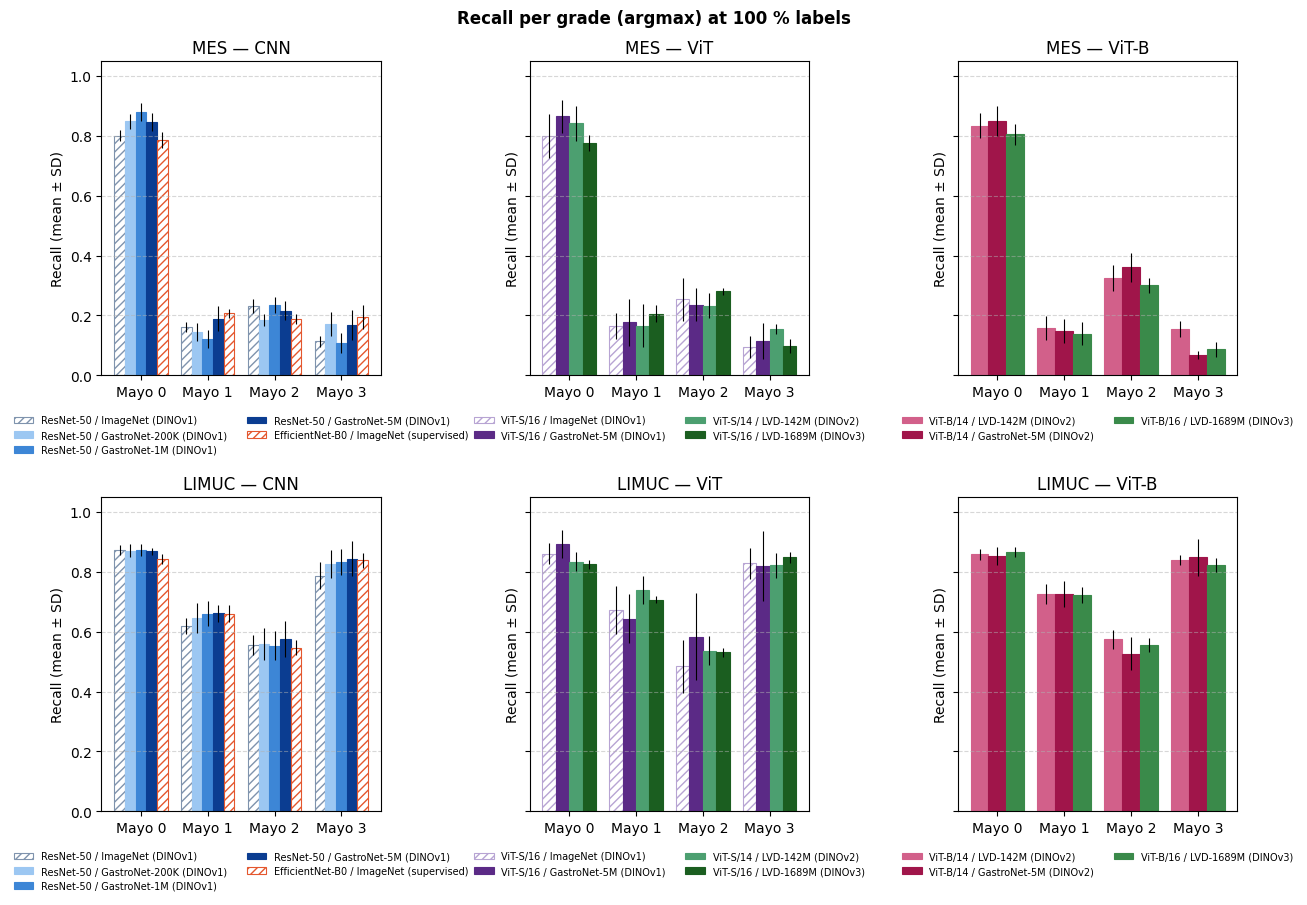

In [10]:
fig, axes = plt.subplots(len(GRADE_DS), len(FAMILY_ORDER), figsize=(13, 4.6 * len(GRADE_DS)), squeeze=False,
                         sharey=True)
for row, ds in zip(axes, GRADE_DS, strict=True):
    sub = RUNS[ds][RUNS[ds]["pct_data"] == FULL_PCT]
    for ax, family in zip(row, FAMILY_ORDER, strict=True):
        stats = sub[sub["model"].isin(FAMILIES[family])].groupby("model", sort=False)[list(RECALL)].agg(["mean", "std"])
        width = 0.8 / len(stats)
        for i, model in enumerate(stats.index):
            imagenet = model_style(model)["markerfacecolor"] == "white"  # ImageNet = open / hatched
            ax.bar(np.arange(len(RECALL)) + (i - (len(stats) - 1) / 2) * width, stats.loc[model].xs("mean", level=1),
                   width, yerr=stats.loc[model].xs("std", level=1), color="white" if imagenet else COLORS[model],
                   edgecolor=COLORS[model], hatch="////" if imagenet else None, linewidth=0.8,
                   error_kw={"linewidth": 0.8}, label=model_label(model))
        ax.set_xticks(range(len(RECALL)), list(RECALL.values()))
        ax.set(title=f"{DATASETS[ds]} — {family}", ylim=(0, 1.05), ylabel="Recall (mean ± SD)")
        ax.grid(axis="y", linestyle="--", alpha=0.5)
        ax.legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
fig.suptitle(f"Recall per grade (argmax) at {FULL_PCT} % labels", fontweight="bold")
fig.tight_layout()
plt.show()

## 6. Confusion-matrix summaries at 100 % labels

Rebuilt from the per-seed metrics and the test class sizes. Binary endpoints: frame counts, mean ± SD over seeds
(positive / negative test frames in brackets). Mayo grades: correct / predicted frames, mean over seeds (n = true
frames). Last cell: full matrices of the best CNNs and ViTs side by side (`CM_TOP` per family, ranked on
validation AUROC; local predictions).

In [11]:
def frame_counts(rate: pd.Series, n: int) -> pd.Series:
    """Per-seed rate × class size: frame counts (integers when the class sizes are those of the metrics)."""
    counts = rate * n
    if not np.allclose(counts, counts.round(), atol=1e-6):
        warnings.warn(f"{rate.name} × {n} is not a count: class sizes do not match the metrics", stacklevel=2)
    return counts


def pm_counts(df: pd.DataFrame, by: pd.Series) -> pd.DataFrame:
    g = df.groupby(by, sort=False)
    return g.mean().map("{:.1f}".format) + " ± " + g.std().map("{:.1f}".format)


BINARY = {  # sensitivity, specificity, positive classes, operating point
    "ulcer": ("tuned_sensitivity", "tuned_specificity", {1}, "ulcer, val-F1 threshold"),
    "mes": ("clin_sensitivity", "clin_specificity", {2, 3}, "active, argmax ≥ 2"),
    "limuc": ("clin_sensitivity", "clin_specificity", {2, 3}, "active, argmax ≥ 2"),
}
blocks = {}
for ds, (sens, spec, pos, rule) in BINARY.items():
    if ds not in RUNS or not TEST[ds]:
        continue
    sub = RUNS[ds][RUNS[ds]["pct_data"] == FULL_PCT]
    n_pos = sum(n for k, n in TEST[ds]["per_class"].items() if k in pos)
    n_neg = TEST[ds]["frames"] - n_pos
    cells = pd.DataFrame({"TP": frame_counts(sub[sens], n_pos), "FN": frame_counts(1 - sub[sens], n_pos),
                          "TN": frame_counts(sub[spec], n_neg), "FP": frame_counts(1 - sub[spec], n_neg)})
    blocks[f"{DATASETS[ds]} — {rule} ({n_pos} / {n_neg})"] = pm_counts(cells, sub["model"].map(model_label))
display(pd.concat(blocks, names=["endpoint", "model"]))

TP  \
endpoint                                     model                                                     
Ulcer — ulcer, val-F1 threshold (934 / 1592) ResNet-50 / ImageNet (DINOv1)              710.2 ± 34.8   
                                             ResNet-50 / GastroNet-200K (DINOv1)        656.2 ± 86.1   
                                             ResNet-50 / GastroNet-1M (DINOv1)          787.8 ± 68.2   
                                             ResNet-50 / GastroNet-5M (DINOv1)          650.0 ± 94.8   
                                             EfficientNet-B0 / ImageNet (supervised)    692.3 ± 45.8   
                                             ViT-S/16 / ImageNet (DINOv1)               709.7 ± 80.2   
                                             ViT-S/16 / GastroNet-5M (DINOv1)           781.4 ± 62.1   
                                             ViT-S/14 / LVD-142M (DINOv2)               771.8 ± 22.5   
                                             ViT-S/16 / LVD-1689M (DINOv3)              771.2 ± 33.5   
                                             ViT-B/14 / LVD-142M (DINOv2)               771.6 ± 31.4   
                                             ViT-B/14 / GastroNet-5M (DINOv2)           856.2 ± 28.5   
                                             ViT-B/16 / LVD-1689M (DINOv3)              716.6 ± 36.4   
MES — active, argmax ≥ 2 (2487 / 2833)       ResNet-50 / ImageNet (DINOv1)             1139.9 ± 69.7   
                                             ResNet-50 / GastroNet-200K (DINOv1)       1095.1 ± 68.0   
                                             ResNet-50 / GastroNet-1M (DINOv1)         1127.7 ± 58.2   
                                             ResNet-50 / GastroNet-5M (DINOv1)         1190.8 ± 56.9   
                                             EfficientNet-B0 / ImageNet (supervised)   1113.3 ± 56.2   
                                             ViT-S/16 / ImageNet (DINOv1)             1122.2 ± 170.8   
                                             ViT-S/16 / GastroNet-5M (DINOv1)         1255.8 ± 101.8   
                                             ViT-S/14 / LVD-142M (DINOv2)              1142.0 ± 95.0   
                                             ViT-S/16 / LVD-1689M (DINOv3)             1269.6 ± 39.0   
                                             ViT-B/14 / LVD-142M (DINOv2)              1255.5 ± 78.1   
                                             ViT-B/14 / GastroNet-5M (DINOv2)         1527.2 ± 123.7   
                                             ViT-B/16 / LVD-1689M (DINOv3)             1227.4 ± 65.5   
LIMUC — active, argmax ≥ 2 (262 / 1260)      ResNet-50 / ImageNet (DINOv1)               222.7 ± 3.1   
                                             ResNet-50 / GastroNet-200K (DINOv1)         225.6 ± 4.8   
                                             ResNet-50 / GastroNet-1M (DINOv1)           225.7 ± 3.0   
                                             ResNet-50 / GastroNet-5M (DINOv1)           229.4 ± 3.7   
                                             EfficientNet-B0 / ImageNet (supervised)     226.9 ± 4.1   
                                             ViT-S/16 / ImageNet (DINOv1)               220.2 ± 10.7   
                                             ViT-S/16 / GastroNet-5M (DINOv1)           227.6 ± 10.5   
                                             ViT-S/14 / LVD-142M (DINOv2)                227.2 ± 6.0   
                                             ViT-S/16 / LVD-1689M (DINOv3)               231.3 ± 1.6   
                                             ViT-B/14 / LVD-142M (DINOv2)                228.8 ± 5.8   
                                             ViT-B/14 / GastroNet-5M (DINOv2)            222.1 ± 5.1   
                                             ViT-B/16 / LVD-1689M (DINOv3)               224.3 ± 3.7   

                                                                                                  FN  \
endpoint                                 

In [12]:
blocks = {}
for ds in GRADE_DS:
    if not TEST[ds]:
        continue
    sub = RUNS[ds][RUNS[ds]["pct_data"] == FULL_PCT]
    n, total = TEST[ds]["per_class"], TEST[ds]["frames"]
    correct = pd.DataFrame({k: frame_counts(sub[f"sens_mayo{k}"], nk) for k, nk in n.items()})
    predicted = correct + pd.DataFrame({k: frame_counts(1 - sub[f"spec_mayo{k}"], total - nk) for k, nk in n.items()})
    if not np.allclose(predicted.sum(axis=1), total):
        warnings.warn(f"{ds}: predicted frames do not add up to the test set", stacklevel=1)
    by = sub["model"].map(model_label)
    c, p = correct.groupby(by, sort=False).mean(), predicted.groupby(by, sort=False).mean()
    blocks[DATASETS[ds]] = pd.DataFrame({f"Mayo {k} (n = {nk})": c[k].map("{:.0f}".format) + " / " + p[k].map("{:.0f}".format)
                                         for k, nk in n.items()})
print(f"Correct / predicted frames per Mayo grade at {FULL_PCT} % (argmax; mean over seeds)")
display(pd.concat(blocks, axis=1))

Correct / predicted frames per Mayo grade at 100 % (argmax; mean over seeds)


MES                    \
                                        Mayo 0 (n = 1311) Mayo 1 (n = 1522)   
model                                                                         
ResNet-50 / ImageNet (DINOv1)                 1050 / 3353         245 / 588   
ResNet-50 / GastroNet-200K (DINOv1)           1114 / 3400         219 / 649   
ResNet-50 / GastroNet-1M (DINOv1)             1154 / 3479         183 / 534   
ResNet-50 / GastroNet-5M (DINOv1)             1110 / 3132         288 / 859   
EfficientNet-B0 / ImageNet (supervised)       1031 / 3106         316 / 877   
ViT-S/16 / ImageNet (DINOv1)                  1047 / 3255         249 / 675   
ViT-S/16 / GastroNet-5M (DINOv1)              1135 / 3249         270 / 634   
ViT-S/14 / LVD-142M (DINOv2)                  1103 / 3363         253 / 626   
ViT-S/16 / LVD-1689M (DINOv3)                 1020 / 2872         313 / 909   
ViT-B/14 / LVD-142M (DINOv2)                  1093 / 3239         241 / 583   
ViT-B/14 / GastroNet-5M (DINOv2)              1114 / 2936         226 / 540   
ViT-B/16 / LVD-1689M (DINOv3)                 1056 / 3153         210 / 630   

                                                                            \
                                        Mayo 2 (n = 1864) Mayo 3 (n = 623)   
model                                                                        
ResNet-50 / ImageNet (DINOv1)                  432 / 1046         71 / 333   
ResNet-50 / GastroNet-200K (DINOv1)             345 / 864        107 / 407   
ResNet-50 / GastroNet-1M (DINOv1)              439 / 1030         67 / 277   
ResNet-50 / GastroNet-5M (DINOv1)               402 / 934        105 / 396   
EfficientNet-B0 / ImageNet (supervised)         352 / 857        120 / 480   
ViT-S/16 / ImageNet (DINOv1)                   472 / 1096         58 / 293   
ViT-S/16 / GastroNet-5M (DINOv1)               441 / 1043         71 / 394   
ViT-S/14 / LVD-142M (DINOv2)                    432 / 949         97 / 382   
ViT-S/16 / LVD-1689M (DINOv3)                  523 / 1205         61 / 334   
ViT-B/14 / LVD-142M (DINOv2)                   606 / 1210         96 / 289   
ViT-B/14 / GastroNet-5M (DINOv2)               673 / 1520         42 / 324   
ViT-B/16 / LVD-1689M (DINOv3)                  561 / 1283         54 / 254   

                                                   LIMUC                   \
                                        Mayo 0 (n = 854) Mayo 1 (n = 406)   
model                                                                       
ResNet-50 / ImageNet (DINOv1)                  746 / 860        251 / 394   
ResNet-50 / GastroNet-200K (DINOv1)            744 / 843        262 / 403   
ResNet-50 / GastroNet-1M (DINOv1)              746 / 842        268 / 407   
ResNet-50 / GastroNet-5M (DINOv1)              742 / 837        269 / 408   
EfficientNet-B0 / ImageNet (supervised)        719 / 809        268 / 430   
ViT-S/16 / ImageNet (DINOv1)                   735 / 831        273 / 429   
ViT-S/16 / GastroNet-5M (DINOv1)               763 / 869        261 / 380   
ViT-S/14 / LVD-142M (DINOv2)                   713 / 782        301 / 475   
ViT-S/16 / LVD-1689M (DINOv3)                  704 / 776        287 / 463   
ViT-B/14 / LVD-142M (DINOv2)                   733 / 809        295 / 446   
ViT-B/14 / GastroNet-5M (DINOv2)               728 / 801        295 / 455   
ViT-B/16 / LVD-1689M (DINOv3)                  740 / 822        293 / 443   

                                                                          
                                        Mayo 2 (n = 163) Mayo 3 (n = 99)  
model                                                                     
ResNet-50 / ImageNet (DINOv1)                   91 / 155        78 / 113  
ResNet-50 / GastroNet-200K (DINOv1)             91 / 154        82 / 123  
ResNet-50 / GastroNet-1M (DINOv1)               90 / 150        82 / 124  
ResNet-50 / GastroNet-5M (DINOv1)               94 / 153        84 / 123  
EfficientNet-B0 

model      val_auroc  \
dataset family rank                                                           
Ulcer   CNN    1           ResNet-50 / GastroNet-5M (DINOv1)  0.958 ± 0.011   
               2           ResNet-50 / GastroNet-1M (DINOv1)  0.952 ± 0.007   
               3         ResNet-50 / GastroNet-200K (DINOv1)  0.935 ± 0.011   
               4     EfficientNet-B0 / ImageNet (supervised)  0.899 ± 0.015   
               5               ResNet-50 / ImageNet (DINOv1)  0.886 ± 0.005   
        ViT    1            ViT-S/16 / GastroNet-5M (DINOv1)  0.972 ± 0.006   
               2                ViT-S/14 / LVD-142M (DINOv2)  0.954 ± 0.007   
               3               ViT-S/16 / LVD-1689M (DINOv3)  0.950 ± 0.006   
               4                ViT-S/16 / ImageNet (DINOv1)  0.921 ± 0.013   
        ViT-B  1            ViT-B/14 / GastroNet-5M (DINOv2)  0.994 ± 0.002   
               2                ViT-B/14 / LVD-142M (DINOv2)  0.971 ± 0.008   
               3               ViT-B/16 / LVD-1689M (DINOv3)  0.949 ± 0.008   
MES     CNN    1               ResNet-50 / ImageNet (DINOv1)  0.833 ± 0.007   
               2           ResNet-50 / GastroNet-5M (DINOv1)  0.830 ± 0.012   
               3         ResNet-50 / GastroNet-200K (DINOv1)  0.823 ± 0.015   
               4           ResNet-50 / GastroNet-1M (DINOv1)  0.819 ± 0.010   
               5     EfficientNet-B0 / ImageNet (supervised)  0.816 ± 0.005   
        ViT    1                ViT-S/14 / LVD-142M (DINOv2)  0.853 ± 0.010   
               2            ViT-S/16 / GastroNet-5M (DINOv1)  0.852 ± 0.009   
               3               ViT-S/16 / LVD-1689M (DINOv3)  0.841 ± 0.006   
               4                ViT-S/16 / ImageNet (DINOv1)  0.839 ± 0.010   
        ViT-B  1            ViT-B/14 / GastroNet-5M (DINOv2)  0.870 ± 0.011   
               2                ViT-B/14 / LVD-142M (DINOv2)  0.868 ± 0.010   
               3               ViT-B/16 / LVD-1689M (DINOv3)  0.860 ± 0.008   
LIMUC   CNN    1           ResNet-50 / GastroNet-5M (DINOv1)  0.941 ± 0.001   
               2           ResNet-50 / GastroNet-1M (DINOv1)  0.939 ± 0.002   
               3         ResNet-50 / GastroNet-200K (DINOv1)  0.938 ± 0.002   
               4               ResNet-50 / ImageNet (DINOv1)  0.934 ± 0.001   
               5     EfficientNet-B0 / ImageNet (supervised)  0.933 ± 0.002   
        ViT    1            ViT-S/16 / GastroNet-5M (DINOv1)  0.947 ± 0.002   
               2                ViT-S/14 / LVD-142M (DINOv2)  0.945 ± 0.001   
               3               ViT-S/16 / LVD-1689M (DINOv3)  0.939 ± 0.001   
               4                ViT-S/16 / ImageNet (DINOv1)  0.936 ± 0.002   
        ViT-B  1            ViT-B/14 / GastroNet-5M (DINOv2)  0.948 ± 0.001   
               2                ViT-B/14 / LVD-142M (DINOv2)  0.948 ± 0.001   
               3               ViT-B/16 / LVD-1689M (DINOv3)  0.946 ± 0.001   

                    test endpoint (not used) shown  
dataset family rank                                 
Ulcer   CNN    1               0.928 ± 0.010     ✓  
               2               0.936 ± 0.011     ✓  
               3               0.915 ± 0.012        
               4               0.867 ± 0.020        
               5               0.794 ± 0.013        
        ViT    1               0.955 ± 0.008     ✓  
               2               0.928 ± 0.007     ✓  
               3               0.904 ± 0.017        
               4               0.892 ± 0.016        
        ViT-B  1               0.981 ± 0.003     ✓  
               2               0.952 ± 0.003     ✓  
               3               0.900 ± 0.022        
MES     CNN    1               0.775 ± 0.008     ✓  
               2               0.763 ± 0.022     ✓  
               3               0.755 ± 0.019        
               4               0.754 ± 0.010        
               5               0.779 ± 0.014        
        ViT    1               0.786 ± 0.010 

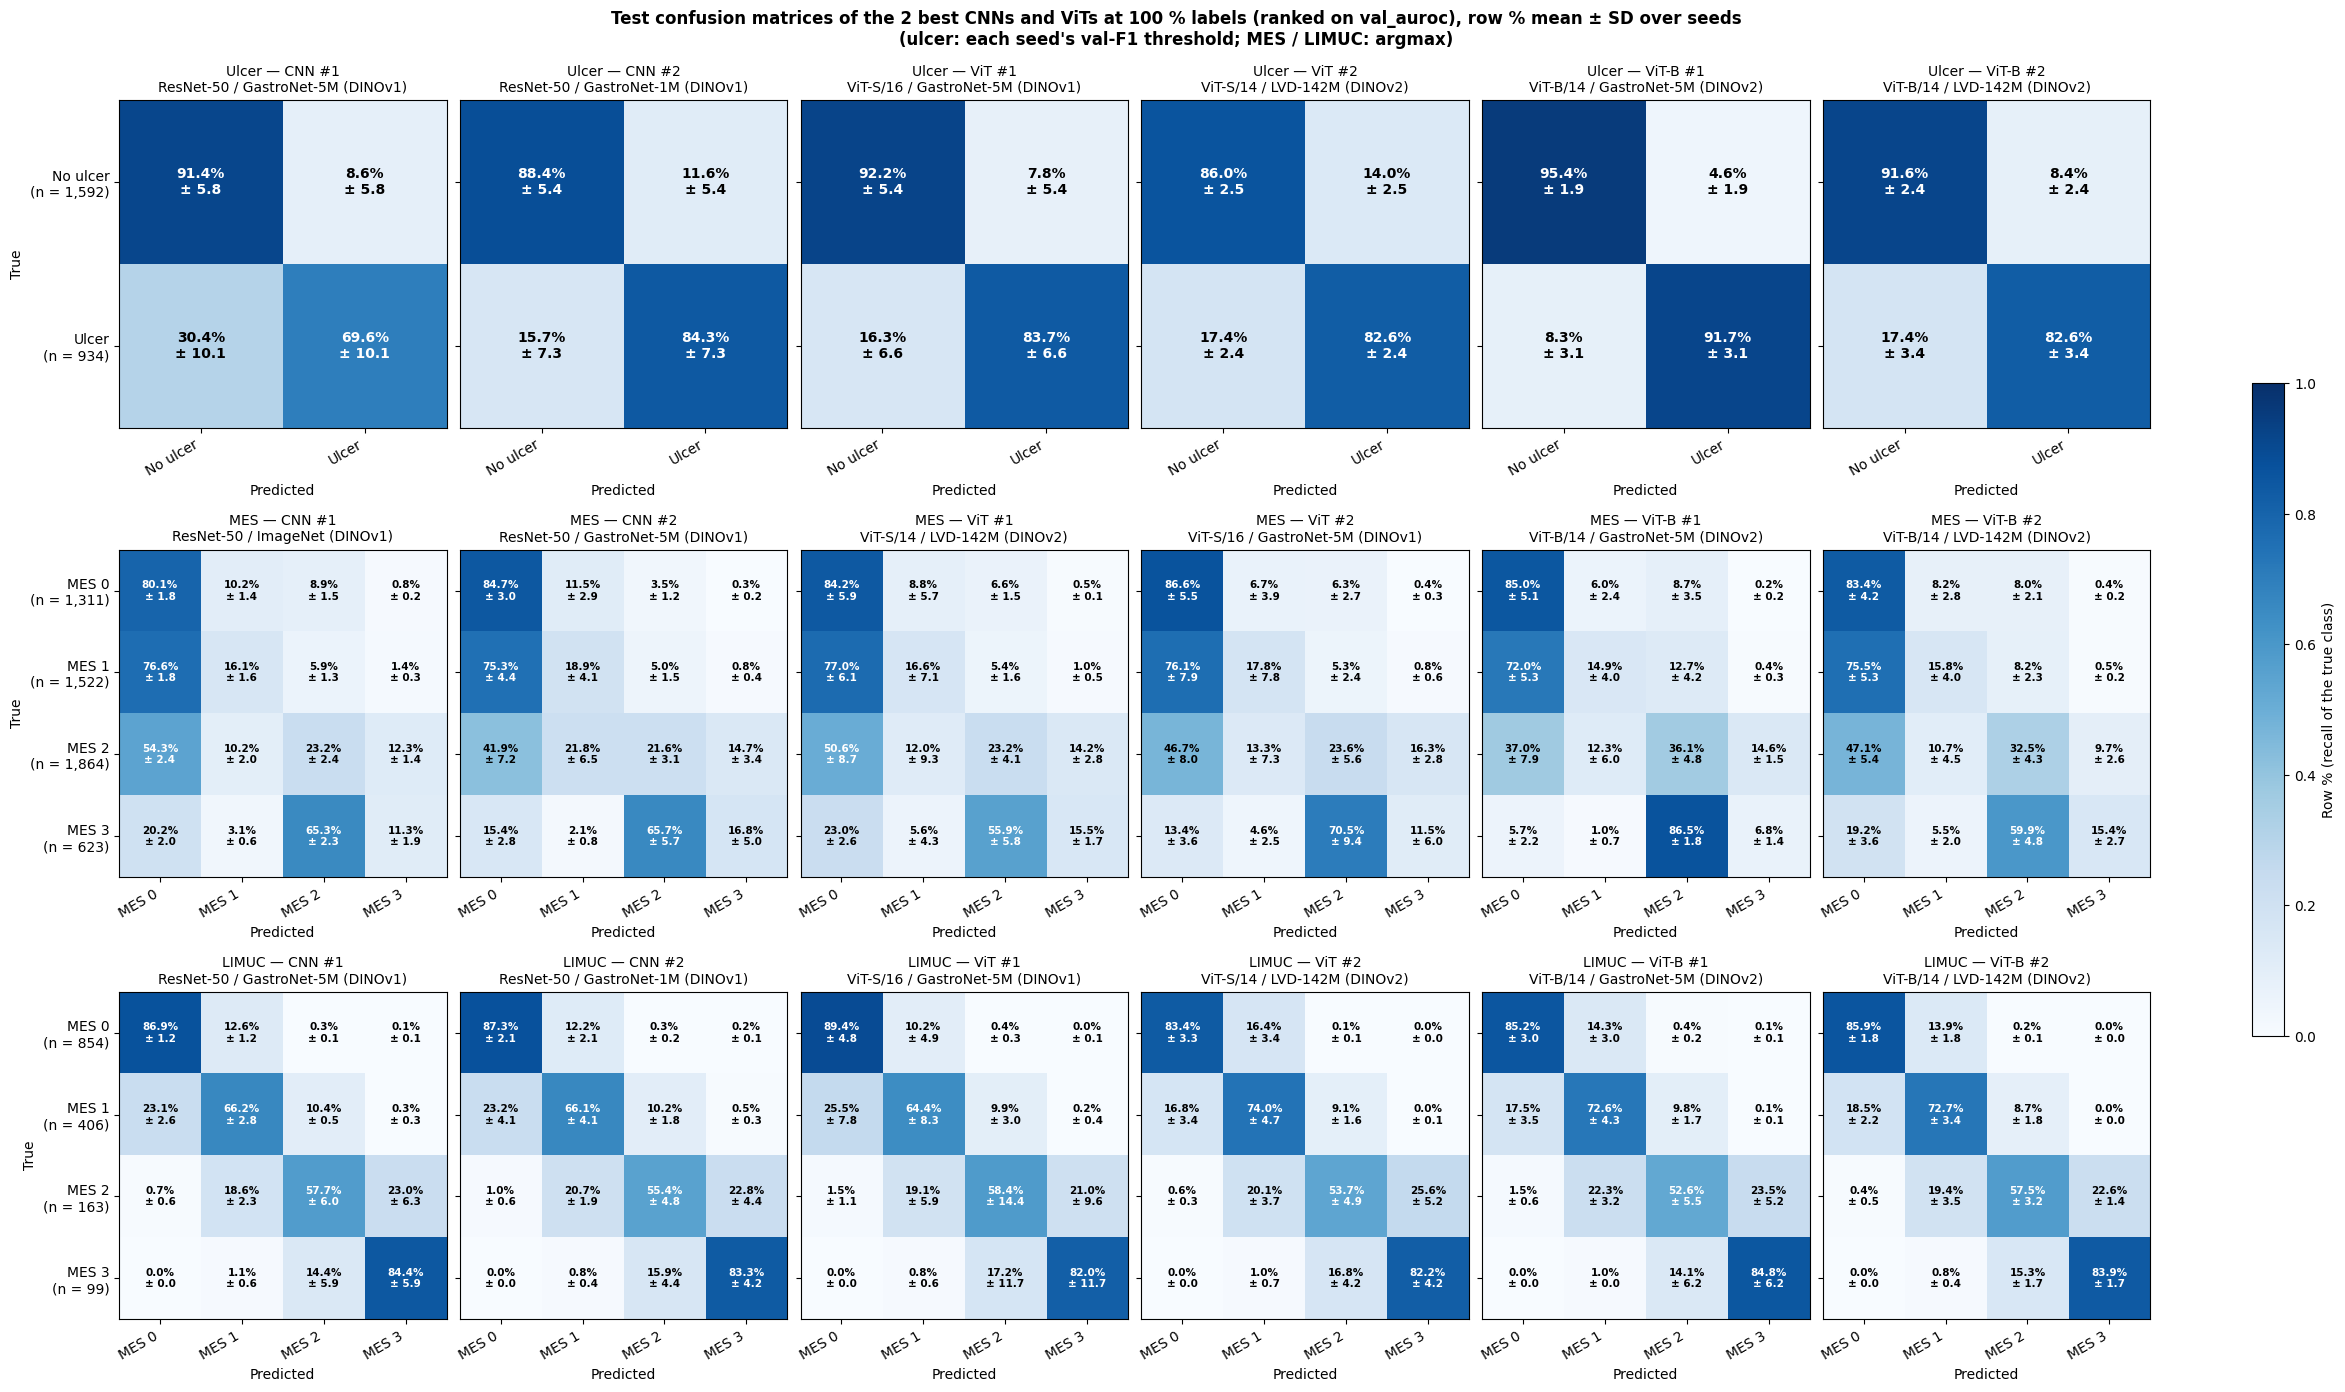

In [13]:
CM_SELECT = "val_auroc"  # ranked on validation, never on the test set
CM_TOP = 2  # models shown per family (CNN, ViT)
CLASS_NAMES = {"ulcer": ULCER_CLASS_NAMES, "mes": MES_CLASS_NAMES, "limuc": MES_CLASS_NAMES}

best, rows = {}, []
for ds in RUNS:
    agg, end = AGG[ds][AGG[ds]["pct_data"] == FULL_PCT].set_index("model"), ENDPOINT_METRIC[ds]
    for family in FAMILY_ORDER:
        ranked = agg.loc[[m for m in FAMILIES[family] if m in agg.index]]
        ranked = ranked.sort_values(f"{CM_SELECT}_mean", ascending=False, kind="stable")  # ties: MODEL_ORDER
        best[ds, family] = list(ranked.index[:CM_TOP])
        rows += [{"dataset": DATASETS[ds], "family": family, "rank": i, "model": model_label(m),
                  CM_SELECT: pm(r[f"{CM_SELECT}_mean"], r[f"{CM_SELECT}_std"]),
                  "test endpoint (not used)": pm(r[f"{end}_mean"], r[f"{end}_std"]),  # notebook 03
                  "shown": "✓" if i <= CM_TOP else ""}
                 for i, (m, r) in enumerate(ranked.iterrows(), 1)]
display(pd.DataFrame(rows).set_index(["dataset", "family", "rank"]))

try:
    cms = {(ds, m): seed_confusions(ds, m) for (ds, _), models in best.items() for m in models}
except FileNotFoundError:
    print("The confusion matrices need the saved test predictions (local only).")
else:
    ncols = CM_TOP * len(FAMILY_ORDER)
    fig, axes = plt.subplots(len(RUNS), ncols, figsize=(3.9 * ncols, 4.6 * len(RUNS)), squeeze=False,
                             layout="constrained")
    for row, ds in zip(axes, RUNS, strict=True):
        shown = [(family, i, m) for family in FAMILY_ORDER for i, m in enumerate(best[ds, family], 1)]
        for c, (ax, (family, i, m)) in enumerate(zip(row, shown, strict=False)):
            f = cms[ds, m]["fractions"]
            n = np.bincount(cms[ds, m]["labels"], minlength=len(CLASS_NAMES[ds]))
            im = draw_mean_cm(ax, f.mean(0), f.std(0, ddof=1), CLASS_NAMES[ds], n,
                               f"{DATASETS[ds]} — {family} #{i}\n{model_label(m)}",
                               10 if ds == "ulcer" else 7.5, show_y=c == 0)
        for ax in row[len(shown):]:  # family with fewer than CM_TOP models
            ax.set_visible(False)
    fig.colorbar(im, ax=axes, shrink=0.5, label="Row % (recall of the true class)")
    fig.suptitle(f"Test confusion matrices of the {CM_TOP} best CNNs and ViTs at {FULL_PCT} % labels (ranked on "
                 f"{CM_SELECT}), row % mean ± SD over seeds\n(ulcer: each seed's val-F1 threshold; MES / LIMUC: "
                 "argmax)", fontweight="bold")
    plt.show()

## 7. Across label fractions

Mean ± SD over seeds per model and nominal fraction, with the mean realised fraction (Section 2).

In [24]:
ACROSS = {
    "ulcer": {"auroc": "frame AUROC", "clip_auroc": "clip AUROC", "tuned_sensitivity": "sens. (val-F1 thr.)",
              "tuned_specificity": "spec. (val-F1 thr.)", "tuned_mcc": "MCC (val-F1 thr.)"},
    "mes": {"auroc": "frame AUROC", "clip_auroc": "clip AUROC", "clin_auroc": "active AUROC", "clin_sens": "active sens.",
            "clin_spec": "active spec.",  "qwk": "QWK"},
    "limuc": {"auroc": "frame AUROC", "clin_auroc": "active AUROC", "clin_sens": "active sens.",
              "clin_spec": "active spec.", "sens_mayo2": "Mayo 2 recall", "qwk": "QWK"},
}
for ds in AGG:
    table = pm_table(ds, ACROSS[ds], pct=None)
    table.insert(0, "realised %", (100 * AGG[ds]["realized_fraction_mean"]).round(1).to_numpy())
    print(f"\n{DATASETS[ds]} (endpoint of notebook 03: {ACROSS[ds][ENDPOINT_METRIC[ds]]})")
    display(table)


Ulcer (endpoint of notebook 03: frame AUROC)


realised %    frame AUROC  \
model                                   nominal %                              
ResNet-50 / ImageNet (DINOv1)           10               10.0  0.691 ± 0.047   
                                        25               25.0  0.775 ± 0.033   
                                        50               50.0  0.789 ± 0.047   
                                        75               75.0  0.790 ± 0.031   
                                        100             100.0  0.794 ± 0.013   
ResNet-50 / GastroNet-200K (DINOv1)     10               10.0  0.837 ± 0.037   
                                        25               25.0  0.884 ± 0.028   
                                        50               50.0  0.899 ± 0.030   
                                        75               75.0  0.903 ± 0.019   
                                        100             100.0  0.915 ± 0.012   
ResNet-50 / GastroNet-1M (DINOv1)       10               10.0  0.843 ± 0.041   
                                        25               25.0  0.899 ± 0.028   
                                        50               50.0  0.917 ± 0.018   
                                        75               75.0  0.922 ± 0.017   
                                        100             100.0  0.936 ± 0.011   
ResNet-50 / GastroNet-5M (DINOv1)       10               10.0  0.851 ± 0.052   
                                        25               25.0  0.899 ± 0.032   
                                        50               50.0  0.916 ± 0.022   
                                        75               75.0  0.925 ± 0.010   
                                        100             100.0  0.928 ± 0.010   
EfficientNet-B0 / ImageNet (supervised) 10               10.0  0.724 ± 0.064   
                                        25               25.0  0.824 ± 0.023   
                                        50               50.0  0.848 ± 0.023   
                                        75               75.0  0.860 ± 0.022   
                                        100             100.0  0.867 ± 0.020   
ViT-S/16 / ImageNet (DINOv1)            10               10.0  0.761 ± 0.047   
                                        25               25.0  0.838 ± 0.027   
                                        50               50.0  0.868 ± 0.023   
                                        75               75.0  0.872 ± 0.015   
                                        100             100.0  0.892 ± 0.016   
ViT-S/16 / GastroNet-5M (DINOv1)        10               10.0  0.830 ± 0.063   
                                        25               25.0  0.904 ± 0.030   
                                        50               50.0  0.937 ± 0.021   
                                        75               75.0  0.948 ± 0.012   
                                        100             100.0  0.955 ± 0.008   
ViT-S/14 / LVD-142M (DINOv2)            10               10.0  0.812 ± 0.061   
                                        25               25.0  0.879 ± 0.039   
                                        50               50.0  0.905 ± 0.017   
                                        75               75.0  0.918 ± 0.011   
                                        100             100.0  0.928 ± 0.007   
ViT-S/16 / LVD-1689M (DINOv3)           10               10.0  0.751 ± 0.064   
                                        25               25.0  0.850 ± 0.033   
                                        50               50.0  0.880 ± 0.027   
                                        75               75.0  0.889 ± 0.017   
                                        100             100.0  0.904 ± 0.017   
ViT-B/14 / LVD-142M (DINOv2)            10               10.0  0.817 ± 0.052   
                                        25               25.0  0.896 ± 0.024   
                                        50               50.0  0.918 ± 0.023   
                                        75         


MES (endpoint of notebook 03: active AUROC)


realised %    frame AUROC  \
model                                   nominal %                              
ResNet-50 / ImageNet (DINOv1)           10               10.0  0.643 ± 0.041   
                                        25               25.0  0.643 ± 0.045   
                                        50               50.0  0.650 ± 0.018   
                                        75               75.0  0.652 ± 0.022   
                                        100             100.0  0.654 ± 0.006   
ResNet-50 / GastroNet-200K (DINOv1)     10               10.0  0.647 ± 0.031   
                                        25               25.0  0.633 ± 0.038   
                                        50               50.0  0.637 ± 0.023   
                                        75               75.0  0.647 ± 0.024   
                                        100             100.0  0.653 ± 0.010   
ResNet-50 / GastroNet-1M (DINOv1)       10               10.0  0.659 ± 0.026   
                                        25               25.0  0.657 ± 0.028   
                                        50               50.0  0.653 ± 0.028   
                                        75               75.0  0.656 ± 0.031   
                                        100             100.0  0.655 ± 0.010   
ResNet-50 / GastroNet-5M (DINOv1)       10               10.0  0.682 ± 0.021   
                                        25               25.0  0.668 ± 0.031   
                                        50               50.0  0.676 ± 0.018   
                                        75               75.0  0.674 ± 0.026   
                                        100             100.0  0.680 ± 0.016   
EfficientNet-B0 / ImageNet (supervised) 10               10.0  0.649 ± 0.038   
                                        25               25.0  0.643 ± 0.028   
                                        50               50.0  0.650 ± 0.017   
                                        75               75.0  0.655 ± 0.026   
                                        100             100.0  0.662 ± 0.008   
ViT-S/16 / ImageNet (DINOv1)            10               10.0  0.628 ± 0.024   
                                        25               25.0  0.618 ± 0.027   
                                        50               50.0  0.622 ± 0.016   
                                        75               75.0  0.632 ± 0.029   
                                        100             100.0  0.636 ± 0.012   
ViT-S/16 / GastroNet-5M (DINOv1)        10               10.0  0.646 ± 0.021   
                                        25               25.0  0.639 ± 0.019   
                                        50               50.0  0.647 ± 0.021   
                                        75               75.0  0.661 ± 0.022   
                                        100             100.0  0.672 ± 0.016   
ViT-S/14 / LVD-142M (DINOv2)            10               10.0  0.672 ± 0.019   
                                        25               25.0  0.656 ± 0.035   
                                        50               50.0  0.659 ± 0.027   
                                        75               75.0  0.665 ± 0.038   
                                        100             100.0  0.660 ± 0.010   
ViT-S/16 / LVD-1689M (DINOv3)           10               10.0  0.695 ± 0.025   
                                        25               25.0  0.682 ± 0.035   
                                        50               50.0  0.674 ± 0.027   
                                        75               75.0  0.680 ± 0.034   
                                        100             100.0  0.673 ± 0.010   
ViT-B/14 / LVD-142M (DINOv2)            10               10.0  0.708 ± 0.014   
                                        25               25.0  0.695 ± 0.037   
                                        50               50.0  0.686 ± 0.028   
                                        75         


LIMUC (endpoint of notebook 03: active AUROC)


realised %    frame AUROC  \
model                                   nominal %                              
ResNet-50 / ImageNet (DINOv1)           1                 1.0  0.628 ± 0.034   
                                        5                 5.0  0.820 ± 0.013   
                                        10               10.0  0.889 ± 0.007   
                                        25               25.0  0.921 ± 0.002   
                                        50               50.0  0.927 ± 0.002   
                                        75               75.0  0.928 ± 0.002   
                                        100             100.0  0.930 ± 0.002   
ResNet-50 / GastroNet-200K (DINOv1)     1                 1.0  0.859 ± 0.011   
                                        5                 5.0  0.904 ± 0.006   
                                        10               10.0  0.915 ± 0.009   
                                        25               25.0  0.924 ± 0.003   
                                        50               50.0  0.931 ± 0.003   
                                        75               75.0  0.933 ± 0.002   
                                        100             100.0  0.935 ± 0.002   
ResNet-50 / GastroNet-1M (DINOv1)       1                 1.0  0.861 ± 0.011   
                                        5                 5.0  0.901 ± 0.010   
                                        10               10.0  0.914 ± 0.006   
                                        25               25.0  0.923 ± 0.004   
                                        50               50.0  0.930 ± 0.003   
                                        75               75.0  0.933 ± 0.003   
                                        100             100.0  0.935 ± 0.003   
ResNet-50 / GastroNet-5M (DINOv1)       1                 1.0  0.864 ± 0.022   
                                        5                 5.0  0.907 ± 0.006   
                                        10               10.0  0.918 ± 0.004   
                                        25               25.0  0.928 ± 0.004   
                                        50               50.0  0.933 ± 0.003   
                                        75               75.0  0.935 ± 0.004   
                                        100             100.0  0.937 ± 0.001   
EfficientNet-B0 / ImageNet (supervised) 1                 1.0  0.671 ± 0.026   
                                        5                 5.0  0.834 ± 0.009   
                                        10               10.0  0.891 ± 0.007   
                                        25               25.0  0.916 ± 0.005   
                                        50               50.0  0.924 ± 0.002   
                                        75               75.0  0.925 ± 0.002   
                                        100             100.0  0.928 ± 0.002   
ViT-S/16 / ImageNet (DINOv1)            1                 1.0  0.796 ± 0.014   
                                        5                 5.0  0.884 ± 0.007   
                                        10               10.0  0.903 ± 0.005   
                                        25               25.0  0.919 ± 0.002   
                                        50               50.0  0.926 ± 0.002   
                                        75               75.0  0.930 ± 0.002   
                                        100             100.0  0.934 ± 0.002   
ViT-S/16 / GastroNet-5M (DINOv1)        1                 1.0  0.861 ± 0.011   
                                        5                 5.0  0.913 ± 0.006   
                                        10               10.0  0.923 ± 0.005   
                                        25               25.0  0.934 ± 0.003   
                                        50               50.0  0.940 ± 0.002   
                                        75               75.0  0.940 ± 0.002   
                                        100        

## 8. CNN vs ViT

Mean ± SD over seeds, CNNs left, ViTs right (ViT-B models in a third panel once they have results). Metrics missing from the results (e.g. QWK or MCC of older runs) are
skipped.

In [15]:
CURVE_METRICS = {
    "ulcer": {"auroc": "frame AUROC", "clip_auroc": "clip AUROC", "tuned_f1": "F1 (val-F1 thr.)",
              "tuned_mcc": "MCC (val-F1 thr.)", "tuned_sensitivity": "sensitivity", "tuned_specificity": "specificity"},
    "mes": {"clin_auroc": "active AUROC", "auroc": "frame AUROC (macro OvR)", "qwk": "QWK", "macro_f1": "macro-F1",
            "clin_f1": "active F1"},
    "limuc": {"clin_auroc": "active AUROC", "auroc": "frame AUROC (macro OvR)", "qwk": "QWK", "macro_f1": "macro-F1"},
}
GAIN_METRICS = {"ulcer": ["auroc", "tuned_mcc"], "mes": ["clin_auroc", "qwk"], "limuc": ["clin_auroc", "qwk"]}
GAIN_PAIRS = {"CNN": ("resnet50_imagenet", ["resnet50_200K", "resnet50_1M", "resnet50_5M"]),  # EfficientNet: no pair
              "ViT": ("vits16_imagenet", ["vits16_gastronet", "vits14_dinov2", "vits16_dinov3"]),
              "ViT-B": ("vitb14_dinov2", ["vitb14_gastronet", "vitb16_dinov3"])}  # vs LVD-142M, not ImageNet
FOCUS_PCT = FULL_PCT
CHANCE = {"auroc": 0.5, "clip_auroc": 0.5, "clin_auroc": 0.5, "qwk": 0.0, "tuned_mcc": 0.0}


def present(ds: str, metrics) -> list[str]:
    """Metrics of the results of `ds` among `metrics`."""
    return [m for m in metrics if f"{m}_mean" in AGG[ds]]


def models_of(ds: str, family: str) -> list[str]:
    return [m for m in FAMILIES[family] if m in set(RUNS[ds]["model"])]

### 8a. Learning curves

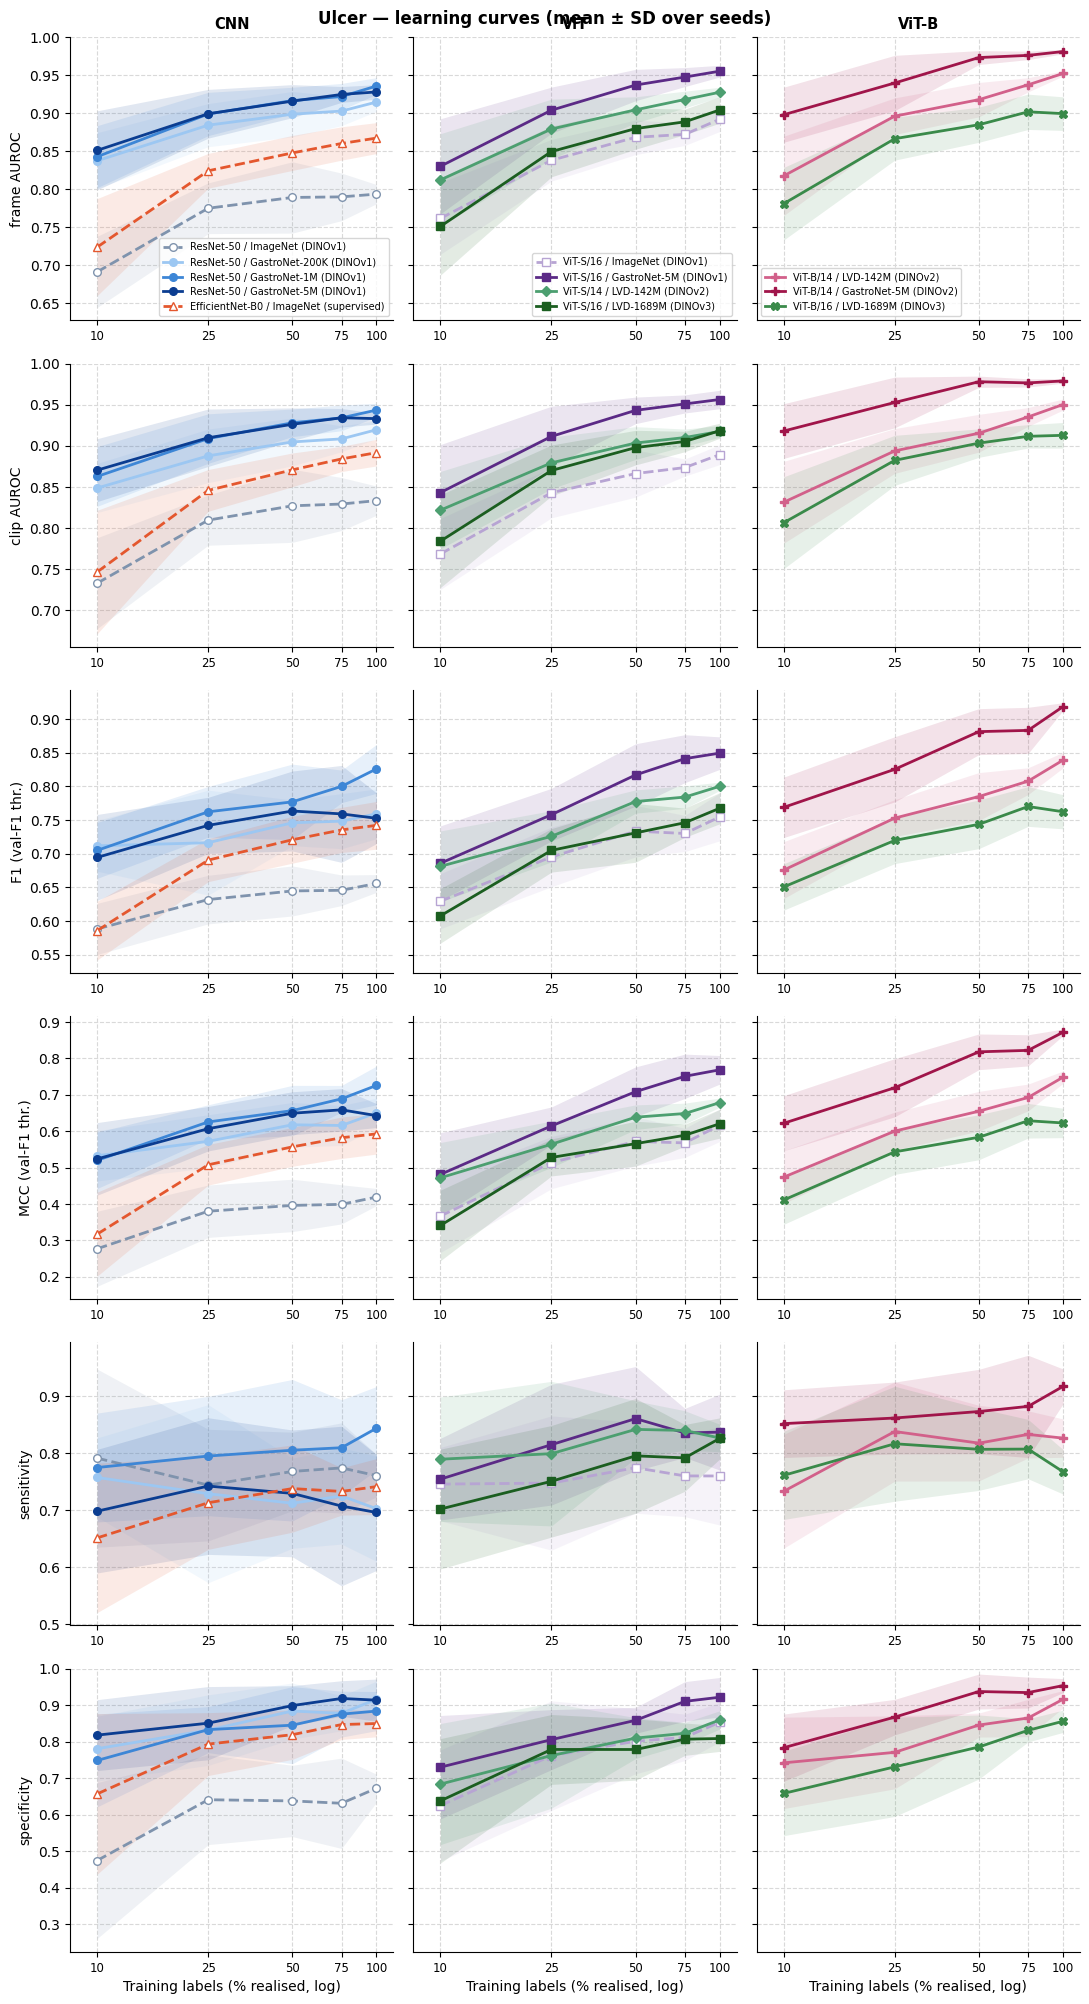

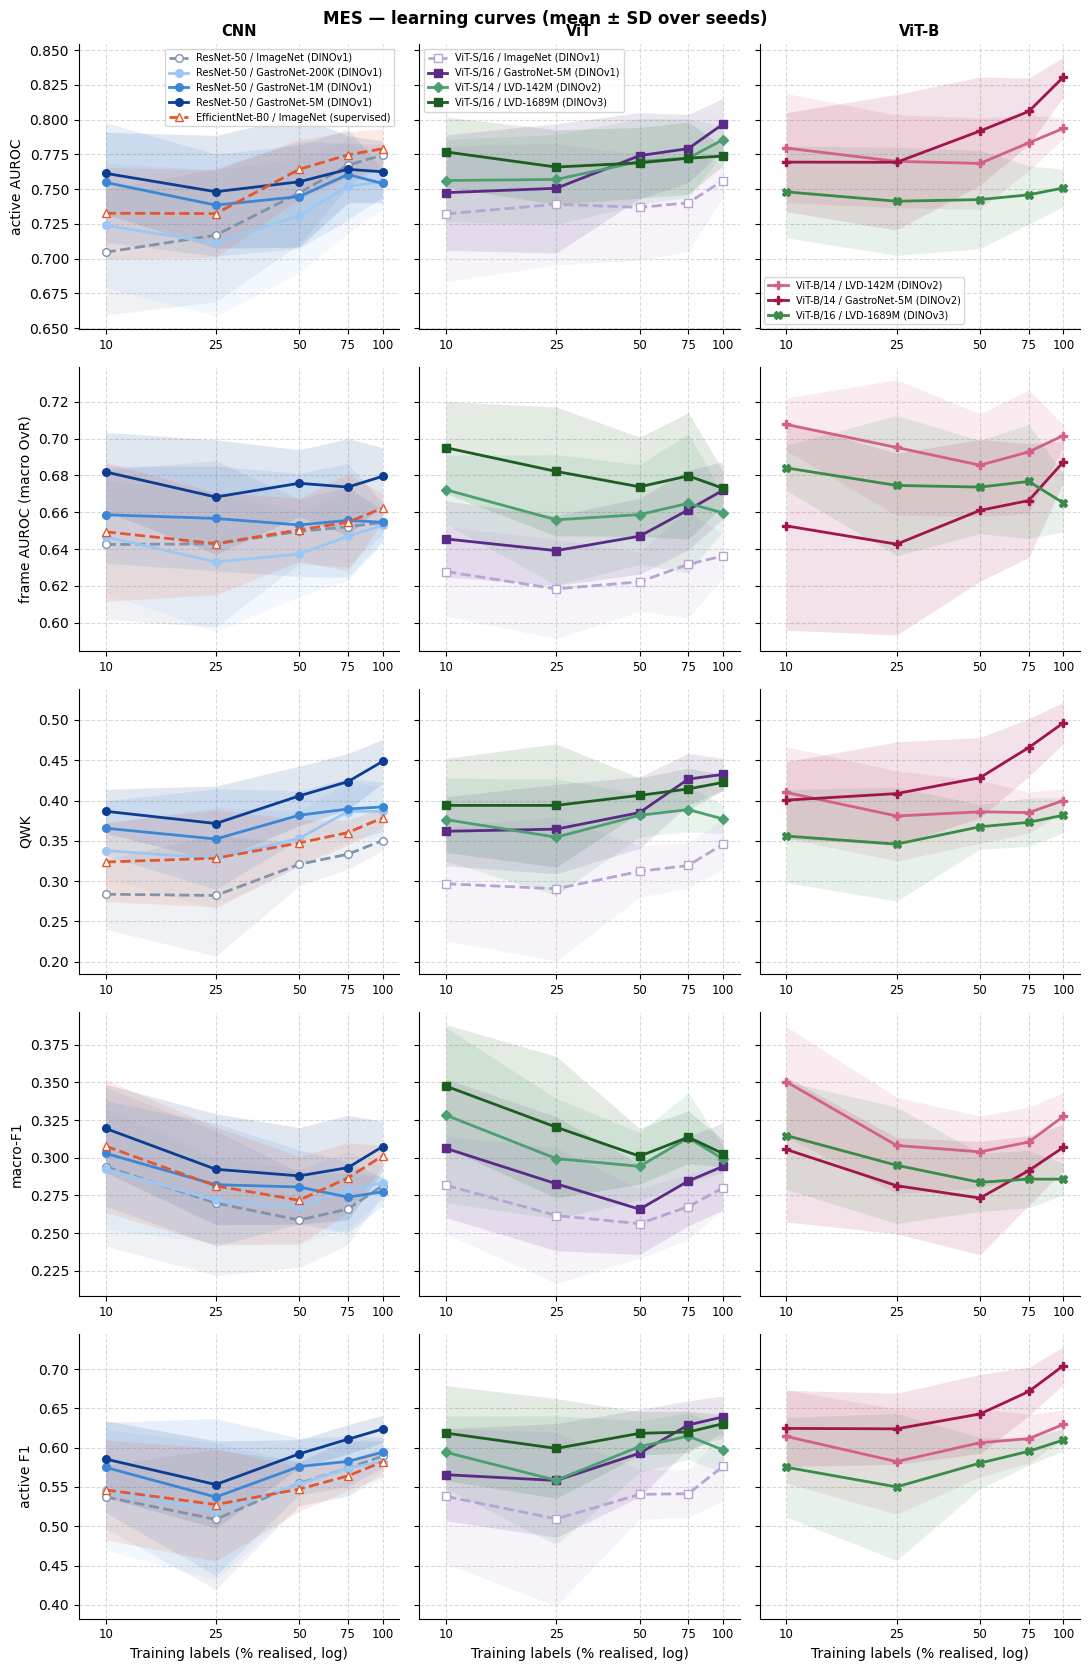

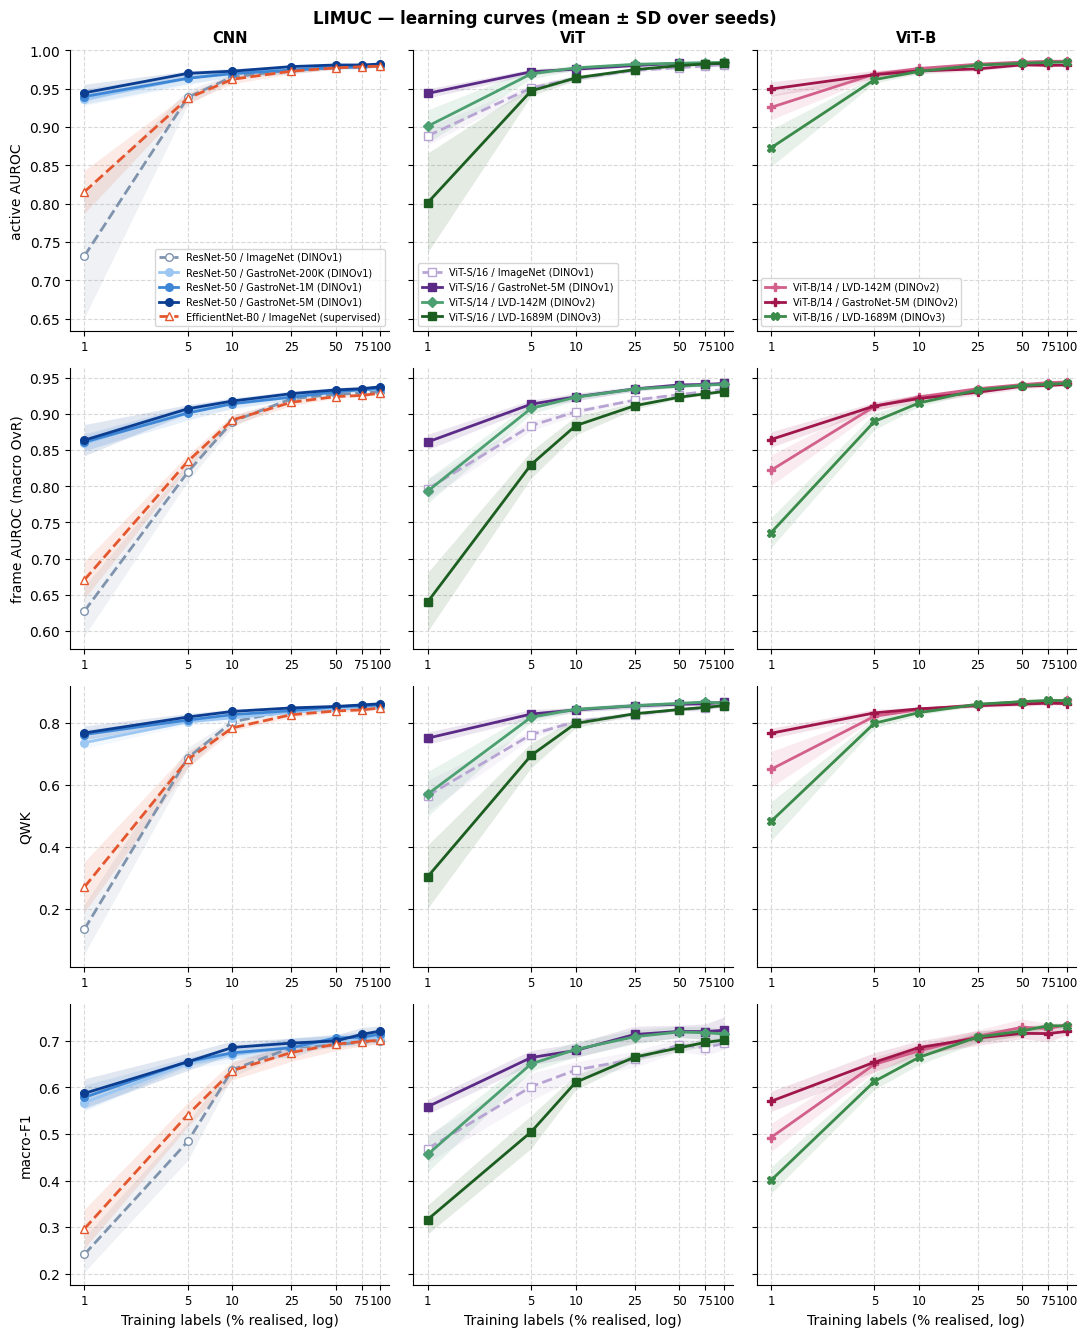

In [16]:
for ds in AGG:
    metrics, ticks = present(ds, CURVE_METRICS[ds]), x_ticks(AGG[ds])
    fig, axes = plt.subplots(len(metrics), len(FAMILY_ORDER), figsize=(11, 3.4 * len(metrics)), squeeze=False,
                             sharey="row")
    for r, metric in enumerate(metrics):
        ylim = y_limits(AGG[ds], metric)
        for c, family in enumerate(FAMILY_ORDER):
            for m in models_of(ds, family):
                draw_curve(axes[r, c], AGG[ds][AGG[ds]["model"] == m], m, metric, band_alpha=0.12)
            curve_axes(axes[r, c], family if r == 0 else "", "Training labels (% realised, log)" if r == len(metrics) - 1
                        else "", CURVE_METRICS[ds][metric] if c == 0 else None, ticks, ylim, chance=CHANCE.get(metric))
    for ax in axes[0]:
        ax.legend(fontsize=7, loc="best")
    fig.suptitle(f"{DATASETS[ds]} — learning curves (mean ± SD over seeds)", fontweight="bold")
    fig.tight_layout()
    plt.show()

### 8b. Heatmaps (mean over seeds)

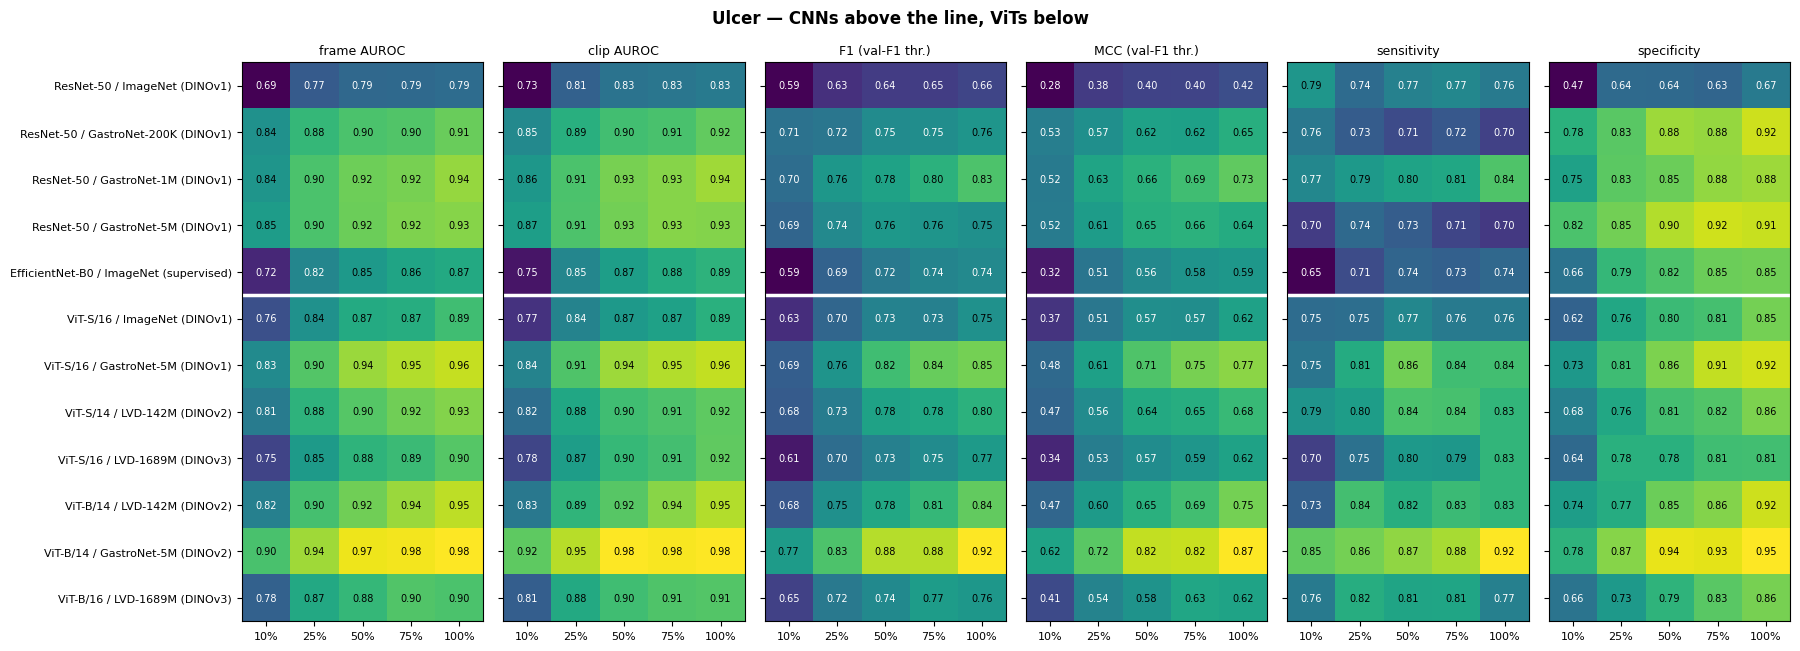

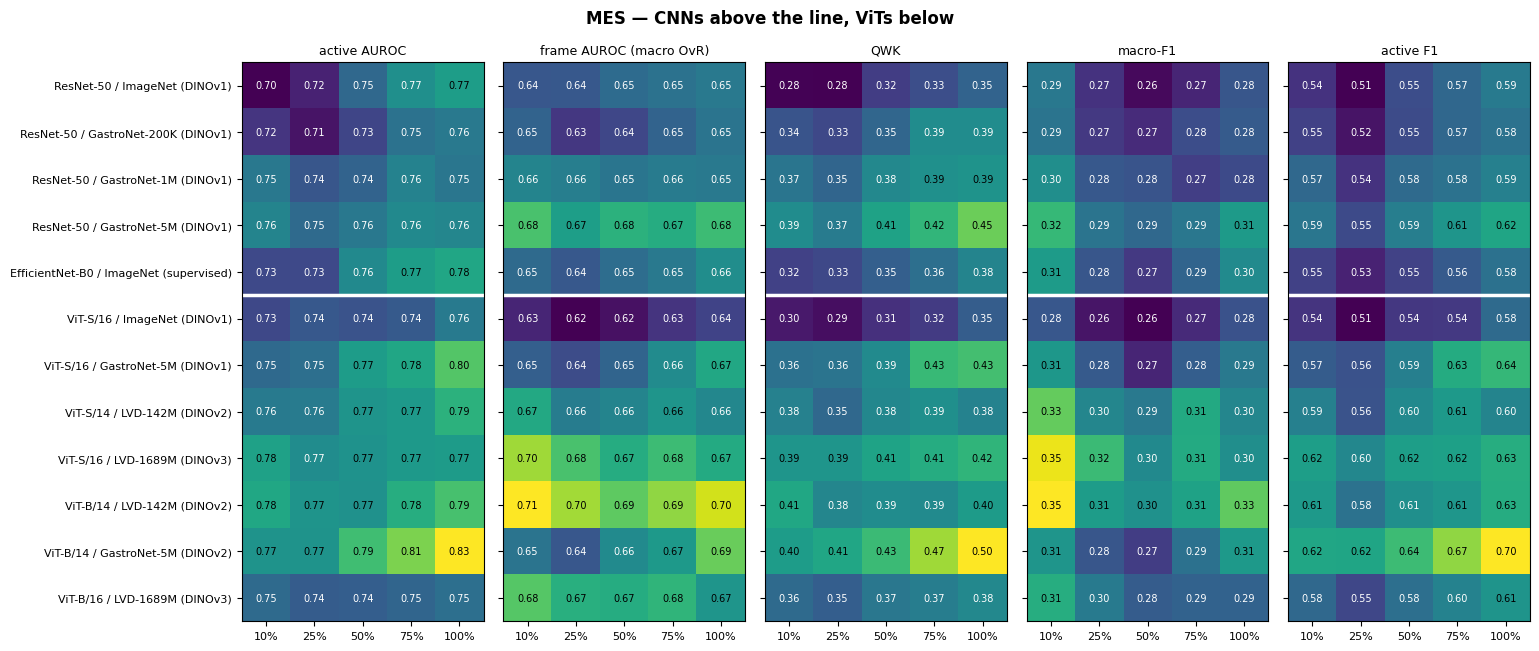

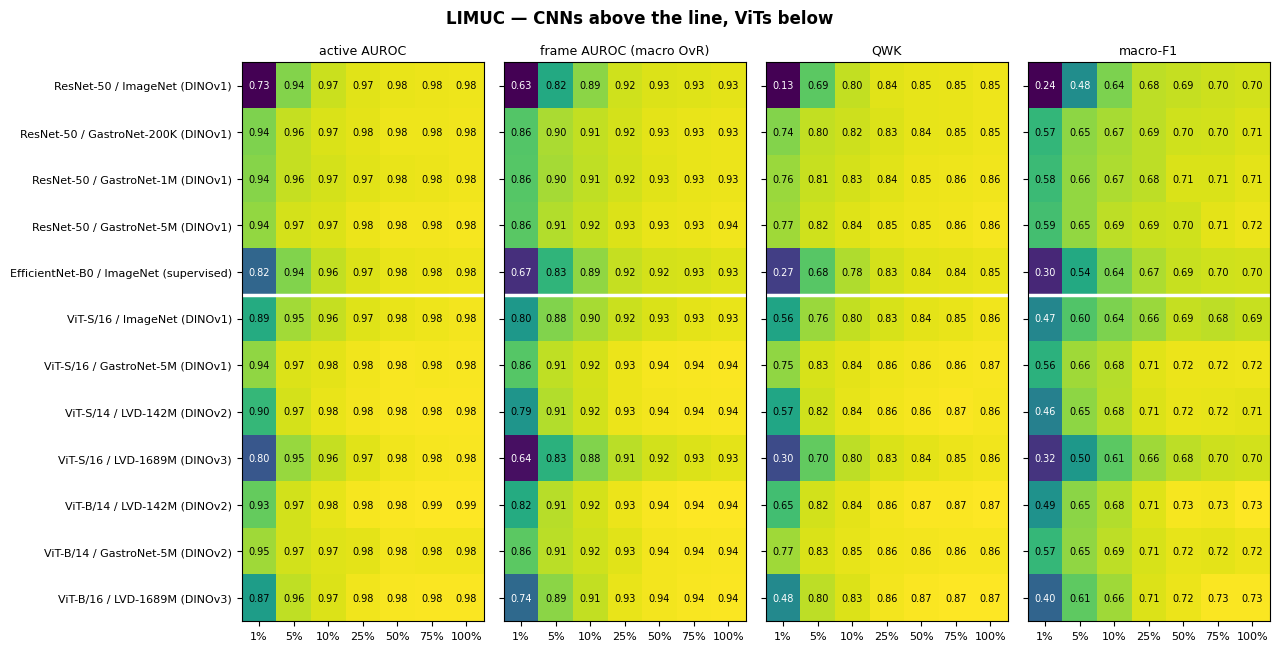

In [17]:
for ds in AGG:
    metrics = present(ds, CURVE_METRICS[ds])
    models = [m for f in FAMILY_ORDER for m in models_of(ds, f)]
    n_cnn = len(models_of(ds, "CNN"))
    fig, axes = plt.subplots(1, len(metrics), figsize=(2.6 * len(metrics) + 2.5, 0.4 * len(models) + 1.8), squeeze=False)
    for i, (ax, metric) in enumerate(zip(axes[0], metrics, strict=True)):
        grid = AGG[ds].pivot(index="model", columns="pct_data", values=f"{metric}_mean").loc[models]
        im = ax.imshow(grid.to_numpy(), cmap="viridis", aspect="auto")
        for (r, c), v in np.ndenumerate(grid.to_numpy()):
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if im.norm(v) < 0.5 else "black")
        ax.axhline(n_cnn - 0.5, color="white", linewidth=2.5)
        ax.set_xticks(range(grid.shape[1]), [f"{p}%" for p in grid.columns], fontsize=8)
        ax.set_yticks(range(len(models)), [model_label(m) for m in models] if i == 0 else [], fontsize=8)
        ax.set_title(CURVE_METRICS[ds][metric], fontsize=9)
    fig.suptitle(f"{DATASETS[ds]} — CNNs above the line, ViTs below", fontweight="bold")
    fig.tight_layout()
    plt.show()

### 8c. Seed spread

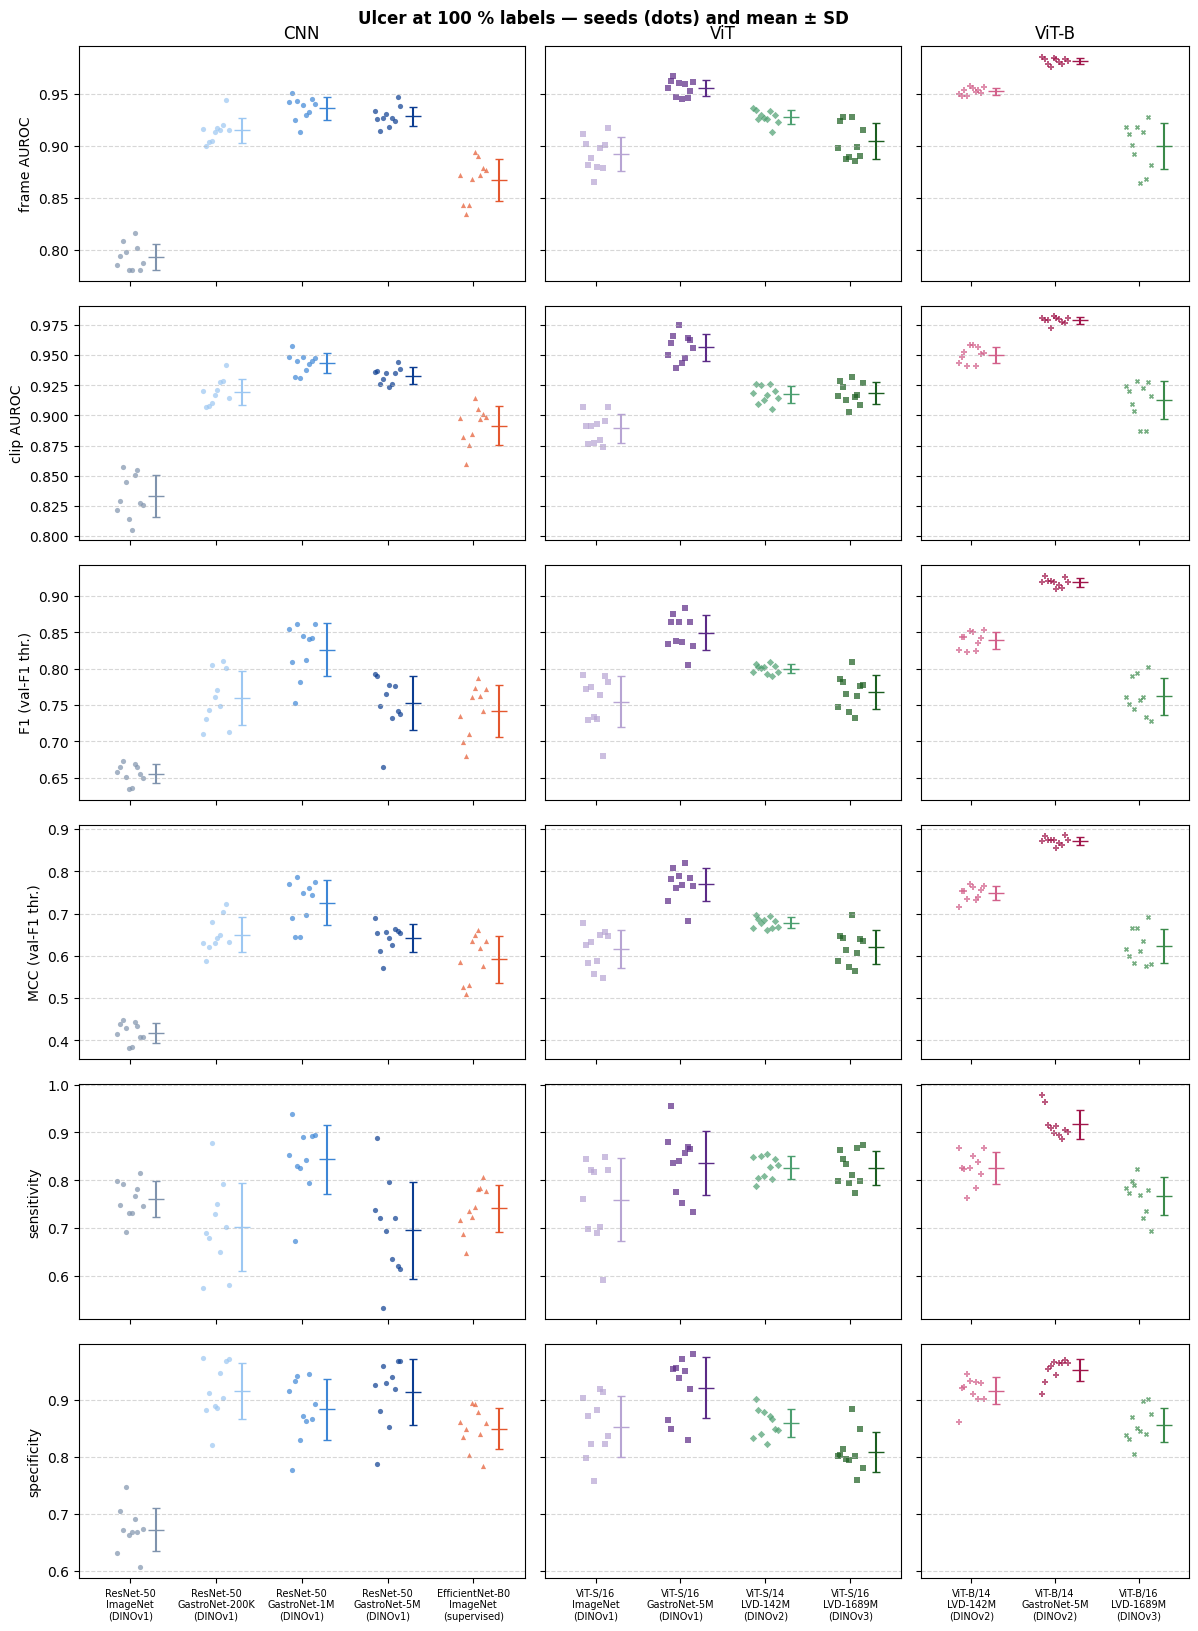

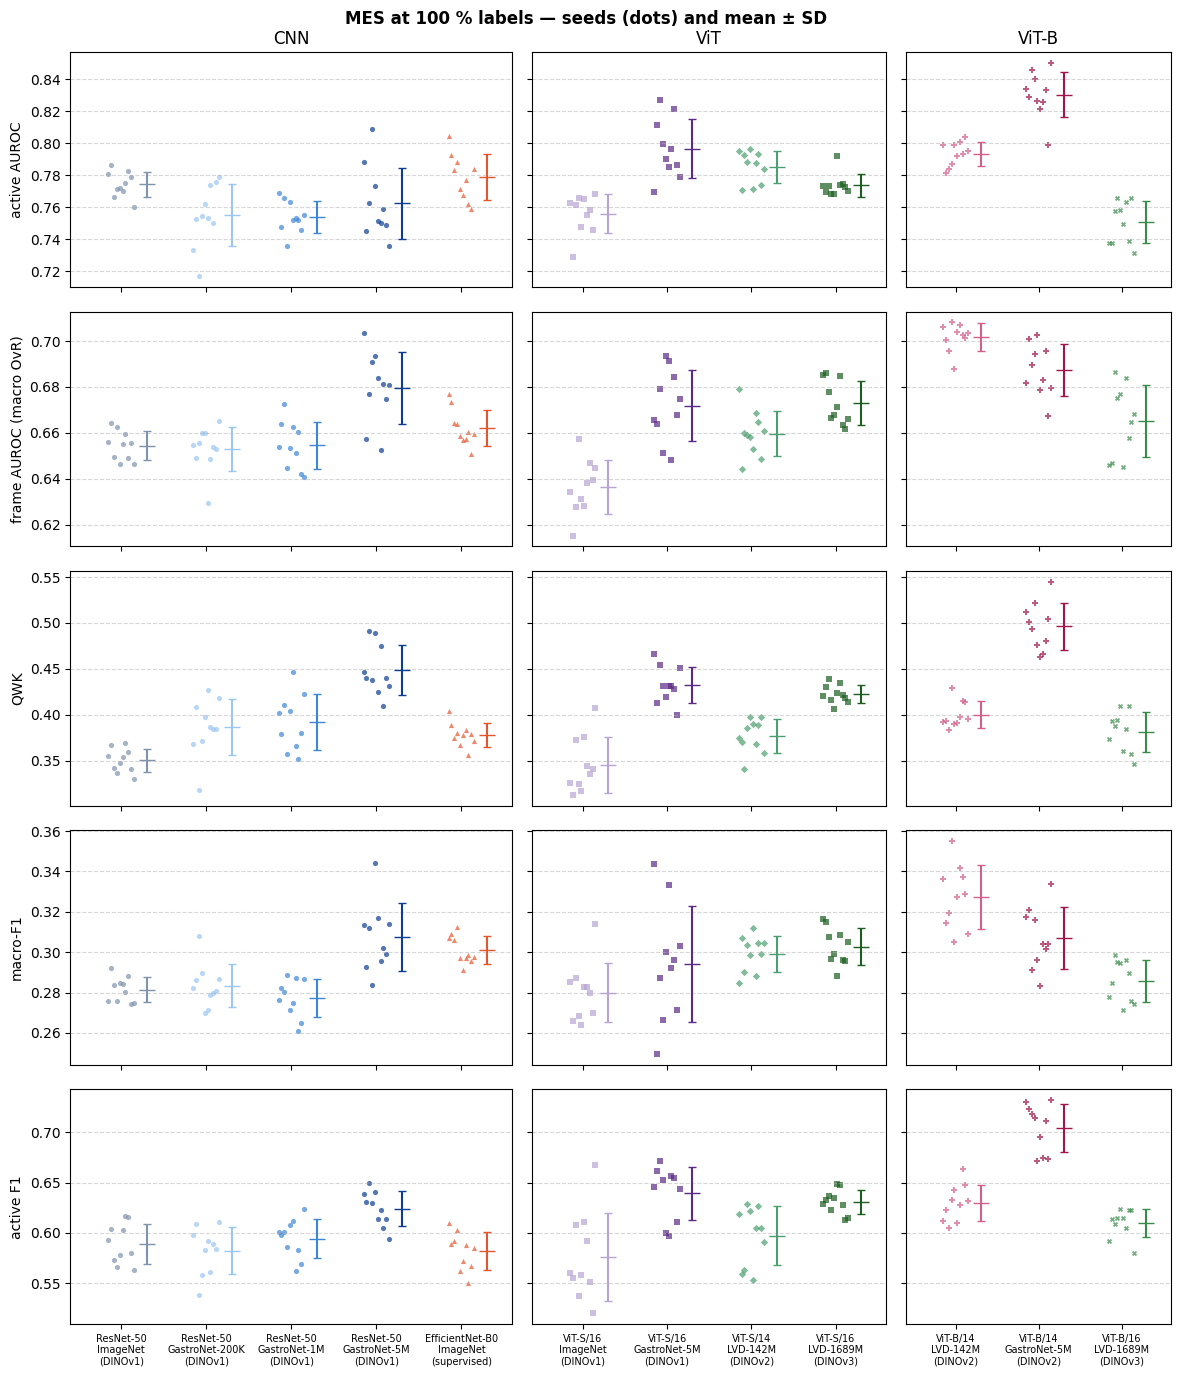

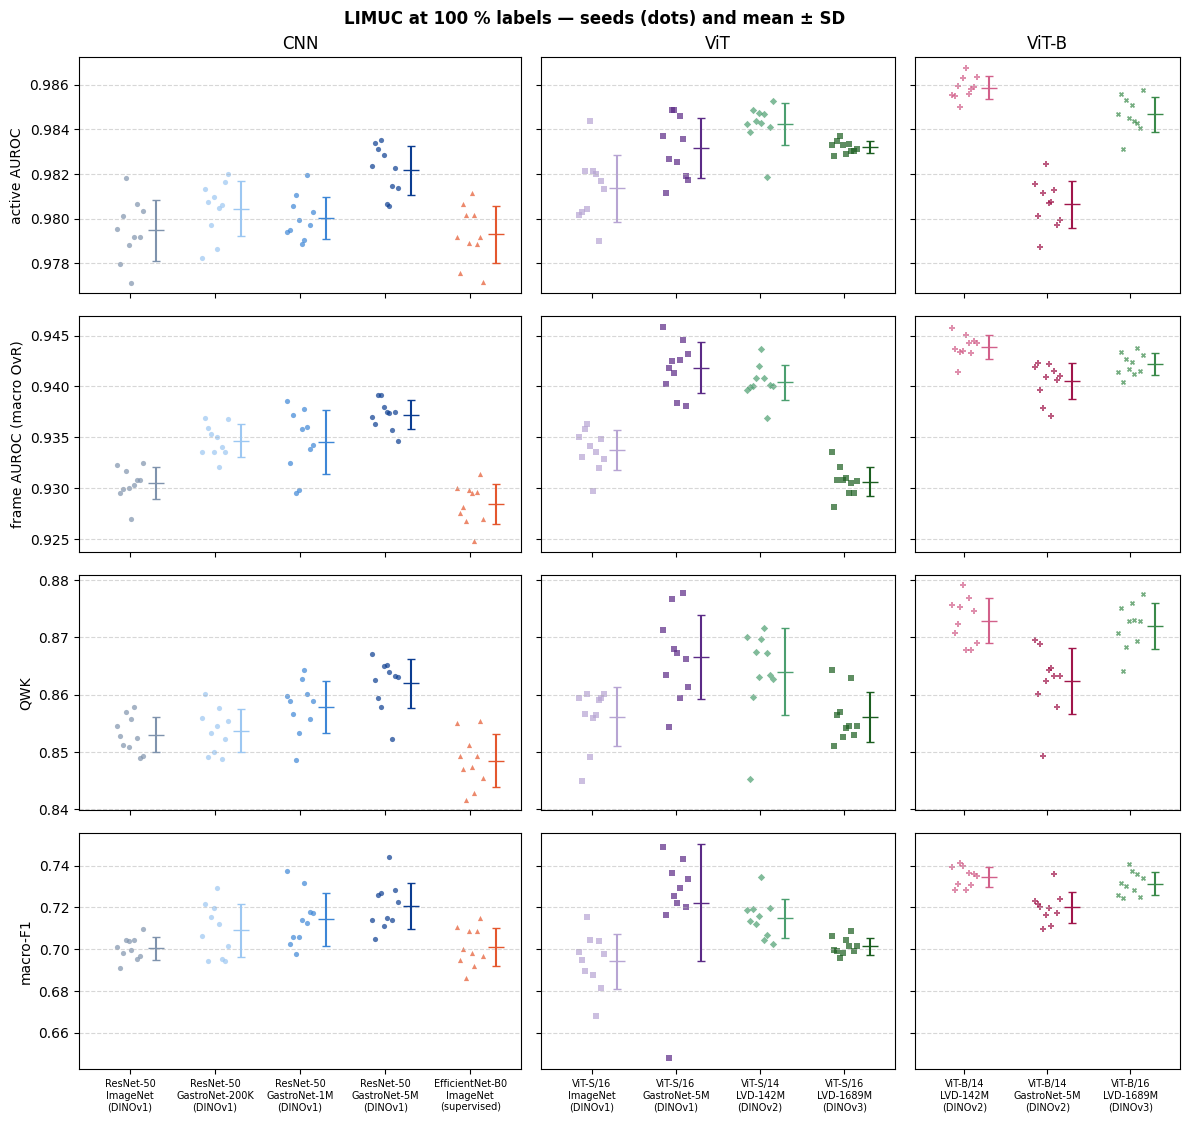

In [18]:
for ds in RUNS:
    metrics = present(ds, CURVE_METRICS[ds])
    sub = RUNS[ds][RUNS[ds]["pct_data"] == FOCUS_PCT]
    widths = [len(models_of(ds, f)) for f in FAMILY_ORDER]
    fig, axes = plt.subplots(len(metrics), len(FAMILY_ORDER), figsize=(12, 2.6 * len(metrics) + 1), squeeze=False,
                             sharey="row", gridspec_kw={"width_ratios": widths})
    for r, metric in enumerate(metrics):
        for c, family in enumerate(FAMILY_ORDER):
            ax, models = axes[r, c], models_of(ds, family)
            for x, m in enumerate(models):
                v, st = sub.loc[sub["model"] == m, metric].to_numpy(float), model_style(m)
                ax.scatter(x + np.linspace(-0.15, 0.15, v.size), v, s=14, color=st["color"], marker=st["marker"],
                           alpha=0.7, linewidths=0)
                ax.errorbar(x + 0.3, np.nanmean(v), yerr=np.nanstd(v, ddof=1), color=st["color"], marker="_",
                            markersize=12, capsize=3)
            last = r == len(metrics) - 1
            ax.set_xticks(range(len(models)), [model_label(m).replace(" / ", "\n").replace(" (", "\n(") for m in models] if last else [],
                          fontsize=7)
            ax.set_xlim(-0.6, len(models) - 0.4)
            ax.grid(axis="y", linestyle="--", alpha=0.5)
            if c == 0:
                ax.set_ylabel(CURVE_METRICS[ds][metric])
            if r == 0:
                ax.set_title(family)
    fig.suptitle(f"{DATASETS[ds]} at {FOCUS_PCT} % labels — seeds (dots) and mean ± SD", fontweight="bold")
    fig.tight_layout()
    plt.show()

### 8d. Gain over the ImageNet model of the same architecture (ViT-B: LVD-142M DINOv2)

Δ per seed (same training subset), mean ± SD; labels = seeds with Δ > 0.

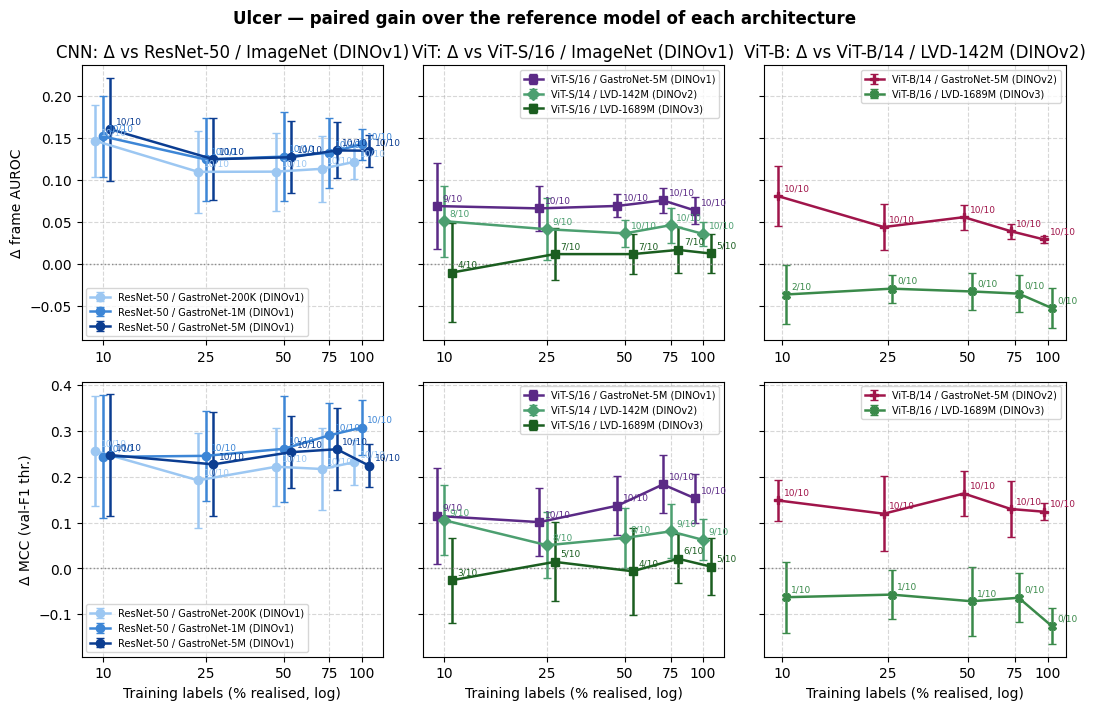

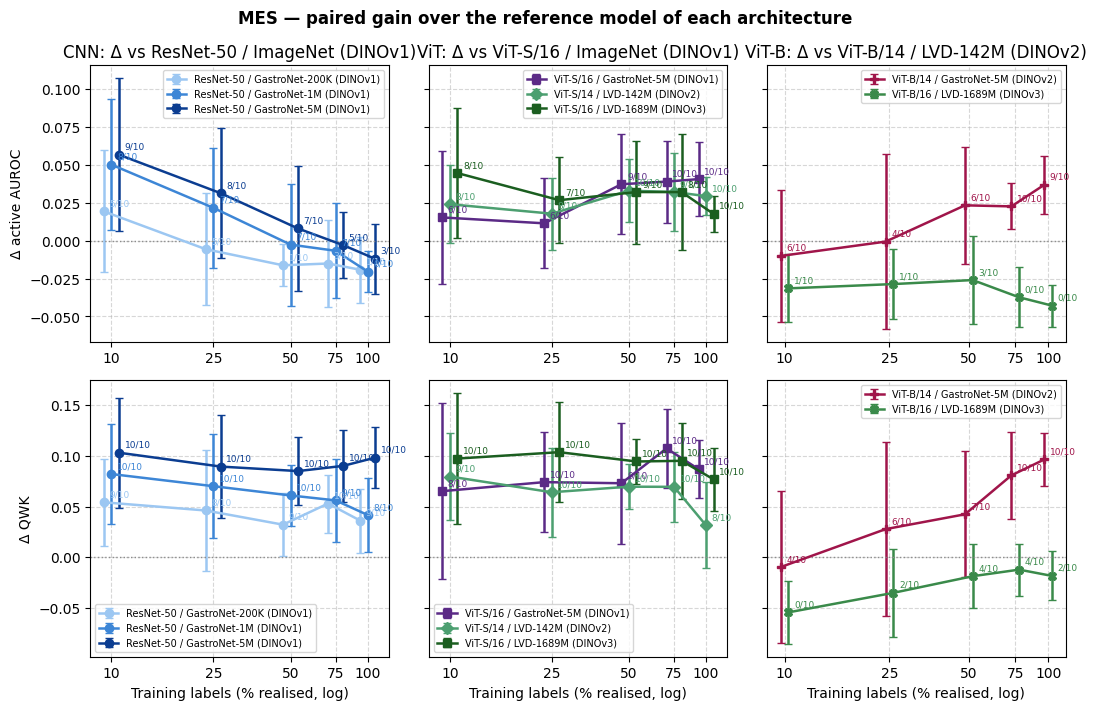

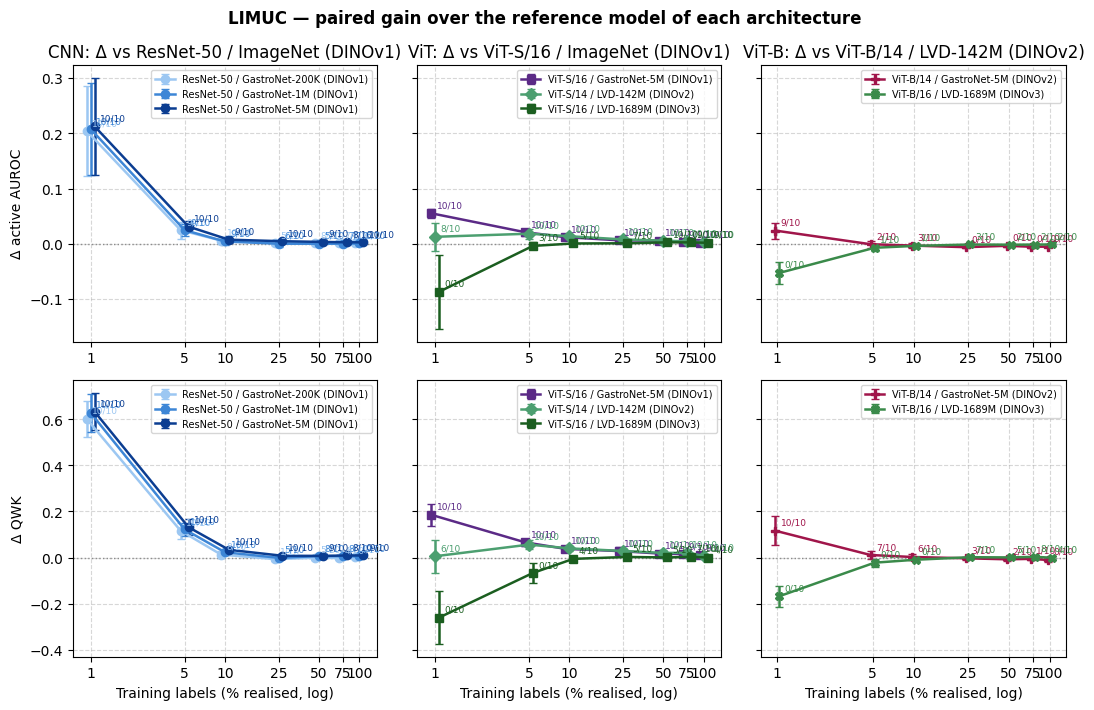

In [19]:
for ds in RUNS:
    metrics = present(ds, GAIN_METRICS[ds])
    x_pct = 100 * RUNS[ds].groupby("pct_data")["realized_fraction"].mean()
    fig, axes = plt.subplots(len(metrics), len(FAMILY_ORDER), figsize=(11, 3.6 * len(metrics)), squeeze=False,
                             sharey="row")
    for r, metric in enumerate(metrics):
        wide = RUNS[ds].pivot_table(index=["pct_data", "seed"], columns="model", values=metric)
        for c, family in enumerate(FAMILY_ORDER):
            ax, (base, challengers) = axes[r, c], GAIN_PAIRS[family]
            shown = [m for m in challengers if {m, base} <= set(wide.columns)]
            for j, m in enumerate(shown):
                d = (wide[m] - wide[base]).dropna().groupby(level="pct_data")
                mean, sd = d.mean(), d.std(ddof=1)
                wins, n = d.apply(lambda s: int((s > 0).sum())), d.size()
                x = x_pct.loc[mean.index].to_numpy() * 1.07 ** (j - (len(shown) - 1) / 2)  # dodge
                ax.errorbar(x, mean, yerr=sd, capsize=3, linewidth=1.8, label=model_label(m), **model_style(m))
                for xi, yi, w, k in zip(x, mean, wins, n, strict=True):
                    ax.annotate(f"{w}/{k}", (xi, yi), textcoords="offset points", xytext=(4, 4), fontsize=6.5,
                                color=COLORS[m])
            ax.axhline(0, color="#8C8C8C", linestyle=":", linewidth=1)
            ax.set_xscale("log")
            ax.set_xticks(x_pct.to_numpy(), [f"{v:.0f}" for v in x_pct])
            ax.minorticks_off()
            ax.grid(linestyle="--", alpha=0.5)
            ax.set(title=f"{family}: Δ vs {model_label(base)}" if r == 0 else "",
                   ylabel=f"Δ {CURVE_METRICS[ds].get(metric, metric)}" if c == 0 else "",
                   xlabel="Training labels (% realised, log)" if r == len(metrics) - 1 else "")
            ax.legend(fontsize=7, loc="best")
    fig.suptitle(f"{DATASETS[ds]} — paired gain over the reference model of each architecture", fontweight="bold")
    fig.tight_layout()
    plt.show()

## 9. External test (internal ↔ LIMUC)

MES runs of each site evaluated on the other site's test split (external; `scripts/mes/evaluate_external.py`), next
to the runs trained on the test split's own site (in-domain), mean ± SD over seeds. Compare within a test split: the
grade mix differs between the test splits (Section 1) and moves every metric that pools grades. At 100 % the two
training splits also differ in size (Section 2). Intervals and contrasts: `03_statistics.ipynb`.

In [20]:
EXTERNAL = {  # test split: (folders of the other site's runs on it, main and ViT-B; their training site)
    "limuc": ([RESULTS["mes"] / "external_LIMUC", RESULTS_VITB["mes"] / "external_LIMUC"], "MES (internal)"),
    "mes": ([RESULTS["limuc"] / "external_internal", RESULTS_VITB["limuc"] / "external_internal"], "LIMUC"),
}
EXT_METRICS = {"clin_auroc": "active AUROC", "auroc": "frame AUROC", "qwk": "QWK", "clin_sens": "active sens.",
               "clin_spec": "active spec."}
EXT_AGG = {}
for ds, (folders, trained_on) in EXTERNAL.items():
    files = [f / "results_per_seed.csv" for f in folders if (f / "results_per_seed.csv").is_file()]
    if ds not in AGG or not files:
        print(f"{DATASETS[ds]} test: no external results")
        continue
    df = pd.concat(map(pd.read_csv, files), ignore_index=True).query("freeze == 'finetune' and head_type == 'linear'")
    print(f"{DATASETS[ds]} test: {len(df)} runs trained on {trained_on} = {df['model'].nunique()} models × "
          f"{df['pct_data'].nunique()} fractions × {df['seed'].nunique()} seeds")
    EXT_AGG[ds] = by_model(aggregate_seed_results(df, "mes"), "pct_data")


def in_vs_external(metrics: dict) -> pd.DataFrame:
    """'mean ± SD' at FULL_PCT; rows (test split, model), columns (metric, in-domain / external)."""
    t = pd.concat({f"{DATASETS[ds]} test": pd.concat({"in-domain": pm_table(ds, metrics),
                                                       "external": pm_table(ds, metrics, agg=agg)}, axis=1)
                   for ds, agg in EXT_AGG.items()}, names=["test split", "model"])
    return t.swaplevel(axis=1)[list(metrics.values())]


if EXT_AGG:
    print(f"\nAt {FULL_PCT} % labels (active disease: argmax ≥ 2)")
    display(in_vs_external(EXT_METRICS))
    print(f"Recall per grade at {FULL_PCT} % labels (argmax)")
    display(in_vs_external(RECALL))

LIMUC test: 600 runs trained on MES (internal) = 12 models × 5 fractions × 10 seeds
MES test: 840 runs trained on LIMUC = 12 models × 7 fractions × 10 seeds

At 100 % labels (active disease: argmax ≥ 2)


active AUROC  \
                                                        in-domain   
test split model                                                    
LIMUC test ResNet-50 / ImageNet (DINOv1)            0.979 ± 0.001   
           ResNet-50 / GastroNet-200K (DINOv1)      0.980 ± 0.001   
           ResNet-50 / GastroNet-1M (DINOv1)        0.980 ± 0.001   
           ResNet-50 / GastroNet-5M (DINOv1)        0.982 ± 0.001   
           EfficientNet-B0 / ImageNet (supervised)  0.979 ± 0.001   
           ViT-S/16 / ImageNet (DINOv1)             0.981 ± 0.001   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.983 ± 0.001   
           ViT-S/14 / LVD-142M (DINOv2)             0.984 ± 0.001   
           ViT-S/16 / LVD-1689M (DINOv3)            0.983 ± 0.000   
           ViT-B/14 / LVD-142M (DINOv2)             0.986 ± 0.001   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.981 ± 0.001   
           ViT-B/16 / LVD-1689M (DINOv3)            0.985 ± 0.001   
MES test   ResNet-50 / ImageNet (DINOv1)            0.775 ± 0.008   
           ResNet-50 / GastroNet-200K (DINOv1)      0.755 ± 0.019   
           ResNet-50 / GastroNet-1M (DINOv1)        0.754 ± 0.010   
           ResNet-50 / GastroNet-5M (DINOv1)        0.763 ± 0.022   
           EfficientNet-B0 / ImageNet (supervised)  0.779 ± 0.014   
           ViT-S/16 / ImageNet (DINOv1)             0.756 ± 0.012   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.797 ± 0.019   
           ViT-S/14 / LVD-142M (DINOv2)             0.786 ± 0.010   
           ViT-S/16 / LVD-1689M (DINOv3)            0.774 ± 0.007   
           ViT-B/14 / LVD-142M (DINOv2)             0.794 ± 0.008   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.831 ± 0.014   
           ViT-B/16 / LVD-1689M (DINOv3)            0.751 ± 0.013   

                                                                   \
                                                         external   
test split model                                                    
LIMUC test ResNet-50 / ImageNet (DINOv1)            0.887 ± 0.012   
           ResNet-50 / GastroNet-200K (DINOv1)      0.920 ± 0.019   
           ResNet-50 / GastroNet-1M (DINOv1)        0.909 ± 0.016   
           ResNet-50 / GastroNet-5M (DINOv1)        0.932 ± 0.014   
           EfficientNet-B0 / ImageNet (supervised)  0.916 ± 0.012   
           ViT-S/16 / ImageNet (DINOv1)             0.894 ± 0.009   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.901 ± 0.018   
           ViT-S/14 / LVD-142M (DINOv2)             0.871 ± 0.014   
           ViT-S/16 / LVD-1689M (DINOv3)            0.891 ± 0.006   
           ViT-B/14 / LVD-142M (DINOv2)             0.897 ± 0.013   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.942 ± 0.008   
           ViT-B/16 / LVD-1689M (DINOv3)            0.860 ± 0.017   
MES test   ResNet-50 / ImageNet (DINOv1)            0.783 ± 0.008   
           ResNet-50 / GastroNet-200K (DINOv1)      0.798 ± 0.012   
           ResNet-50 / GastroNet-1M (DINOv1)        0.804 ± 0.011   
           ResNet-50 / GastroNet-5M (DINOv1)        0.775 ± 0.019   
           EfficientNet-B0 / ImageNet (supervised)  0.801 ± 0.004   
           ViT-S/16 / ImageNet (DINOv1)             0.776 ± 0.010   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.817 ± 0.010   
           ViT-S/14 / LVD-142M (DINOv2)             0.785 ± 0.009   
           ViT-S/16 / LVD-1689M (DINOv3)            0.787 ± 0.002   
           ViT-B/14 / LVD-142M (DINOv2)             0.797 ± 0.004   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.814 ± 0.008   
           ViT-B/16 / LVD-1689M (DINOv3)            0.788 ± 0.005   

                                                      frame AUROC  \
                                                        in-domain   
test split model                                                    
LIMUC test ResNet-50 / ImageNet (DINOv1)            0.930 ± 0.002   
           ResNet-50 / GastroNet-200K (DINOv1)   

Recall per grade at 100 % labels (argmax)


Mayo 0  \
                                                        in-domain   
test split model                                                    
LIMUC test ResNet-50 / ImageNet (DINOv1)            0.873 ± 0.018   
           ResNet-50 / GastroNet-200K (DINOv1)      0.871 ± 0.021   
           ResNet-50 / GastroNet-1M (DINOv1)        0.873 ± 0.021   
           ResNet-50 / GastroNet-5M (DINOv1)        0.869 ± 0.012   
           EfficientNet-B0 / ImageNet (supervised)  0.842 ± 0.017   
           ViT-S/16 / ImageNet (DINOv1)             0.861 ± 0.036   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.894 ± 0.048   
           ViT-S/14 / LVD-142M (DINOv2)             0.834 ± 0.033   
           ViT-S/16 / LVD-1689M (DINOv3)            0.825 ± 0.014   
           ViT-B/14 / LVD-142M (DINOv2)             0.859 ± 0.018   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.852 ± 0.030   
           ViT-B/16 / LVD-1689M (DINOv3)            0.867 ± 0.016   
MES test   ResNet-50 / ImageNet (DINOv1)            0.801 ± 0.018   
           ResNet-50 / GastroNet-200K (DINOv1)      0.849 ± 0.025   
           ResNet-50 / GastroNet-1M (DINOv1)        0.880 ± 0.029   
           ResNet-50 / GastroNet-5M (DINOv1)        0.847 ± 0.030   
           EfficientNet-B0 / ImageNet (supervised)  0.786 ± 0.025   
           ViT-S/16 / ImageNet (DINOv1)             0.798 ± 0.074   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.866 ± 0.055   
           ViT-S/14 / LVD-142M (DINOv2)             0.842 ± 0.059   
           ViT-S/16 / LVD-1689M (DINOv3)            0.778 ± 0.027   
           ViT-B/14 / LVD-142M (DINOv2)             0.834 ± 0.042   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.850 ± 0.051   
           ViT-B/16 / LVD-1689M (DINOv3)            0.805 ± 0.036   

                                                                   \
                                                         external   
test split model                                                    
LIMUC test ResNet-50 / ImageNet (DINOv1)            0.981 ± 0.009   
           ResNet-50 / GastroNet-200K (DINOv1)      0.961 ± 0.039   
           ResNet-50 / GastroNet-1M (DINOv1)        0.963 ± 0.026   
           ResNet-50 / GastroNet-5M (DINOv1)        0.949 ± 0.041   
           EfficientNet-B0 / ImageNet (supervised)  0.951 ± 0.023   
           ViT-S/16 / ImageNet (DINOv1)             0.918 ± 0.036   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.806 ± 0.076   
           ViT-S/14 / LVD-142M (DINOv2)             0.873 ± 0.049   
           ViT-S/16 / LVD-1689M (DINOv3)            0.778 ± 0.015   
           ViT-B/14 / LVD-142M (DINOv2)             0.821 ± 0.048   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.837 ± 0.051   
           ViT-B/16 / LVD-1689M (DINOv3)            0.846 ± 0.038   
MES test   ResNet-50 / ImageNet (DINOv1)            0.496 ± 0.058   
           ResNet-50 / GastroNet-200K (DINOv1)      0.681 ± 0.074   
           ResNet-50 / GastroNet-1M (DINOv1)        0.721 ± 0.138   
           ResNet-50 / GastroNet-5M (DINOv1)        0.731 ± 0.105   
           EfficientNet-B0 / ImageNet (supervised)  0.363 ± 0.039   
           ViT-S/16 / ImageNet (DINOv1)             0.607 ± 0.106   
           ViT-S/16 / GastroNet-5M (DINOv1)         0.756 ± 0.110   
           ViT-S/14 / LVD-142M (DINOv2)             0.334 ± 0.058   
           ViT-S/16 / LVD-1689M (DINOv3)            0.597 ± 0.043   
           ViT-B/14 / LVD-142M (DINOv2)             0.576 ± 0.047   
           ViT-B/14 / GastroNet-5M (DINOv2)         0.711 ± 0.066   
           ViT-B/16 / LVD-1689M (DINOv3)            0.664 ± 0.053   

                                                           Mayo 1  \
                                                        in-domain   
test split model                                                    
LIMUC test ResNet-50 / ImageNet (DINOv1)            0.619 ± 0.027   
           ResNet-50 / GastroNet-200K (DINOv1)      0.6

In [21]:
for ds, agg in EXT_AGG.items():
    table = pm_table(ds, {"clin_auroc": "active AUROC", "auroc": "frame AUROC", "qwk": "QWK"}, pct=None, agg=agg)
    table.insert(0, "realised %", (100 * agg["realized_fraction_mean"]).round(1).to_numpy())
    print(f"\n{DATASETS[ds]} test, runs trained on {EXTERNAL[ds][1]} (realised % of their own training split)")
    display(table)


LIMUC test, runs trained on MES (internal) (realised % of their own training split)


realised %   active AUROC  \
model                                   nominal %                              
ResNet-50 / ImageNet (DINOv1)           10               10.0  0.819 ± 0.055   
                                        25               25.0  0.848 ± 0.051   
                                        50               50.0  0.870 ± 0.023   
                                        75               75.0  0.877 ± 0.015   
                                        100             100.0  0.887 ± 0.012   
ResNet-50 / GastroNet-200K (DINOv1)     10               10.0  0.903 ± 0.023   
                                        25               25.0  0.904 ± 0.024   
                                        50               50.0  0.916 ± 0.016   
                                        75               75.0  0.915 ± 0.022   
                                        100             100.0  0.920 ± 0.019   
ResNet-50 / GastroNet-1M (DINOv1)       10               10.0  0.902 ± 0.041   
                                        25               25.0  0.909 ± 0.036   
                                        50               50.0  0.919 ± 0.020   
                                        75               75.0  0.911 ± 0.021   
                                        100             100.0  0.909 ± 0.016   
ResNet-50 / GastroNet-5M (DINOv1)       10               10.0  0.903 ± 0.030   
                                        25               25.0  0.893 ± 0.038   
                                        50               50.0  0.919 ± 0.018   
                                        75               75.0  0.905 ± 0.039   
                                        100             100.0  0.932 ± 0.014   
EfficientNet-B0 / ImageNet (supervised) 10               10.0  0.826 ± 0.073   
                                        25               25.0  0.842 ± 0.048   
                                        50               50.0  0.886 ± 0.021   
                                        75               75.0  0.903 ± 0.015   
                                        100             100.0  0.916 ± 0.012   
ViT-S/16 / ImageNet (DINOv1)            10               10.0  0.849 ± 0.059   
                                        25               25.0  0.872 ± 0.048   
                                        50               50.0  0.896 ± 0.021   
                                        75               75.0  0.890 ± 0.019   
                                        100             100.0  0.894 ± 0.009   
ViT-S/16 / GastroNet-5M (DINOv1)        10               10.0  0.914 ± 0.037   
                                        25               25.0  0.920 ± 0.031   
                                        50               50.0  0.929 ± 0.017   
                                        75               75.0  0.909 ± 0.034   
                                        100             100.0  0.901 ± 0.018   
ViT-S/14 / LVD-142M (DINOv2)            10               10.0  0.887 ± 0.055   
                                        25               25.0  0.900 ± 0.037   
                                        50               50.0  0.900 ± 0.033   
                                        75               75.0  0.887 ± 0.032   
                                        100             100.0  0.871 ± 0.014   
ViT-S/16 / LVD-1689M (DINOv3)           10               10.0  0.905 ± 0.027   
                                        25               25.0  0.913 ± 0.039   
                                        50               50.0  0.919 ± 0.025   
                                        75               75.0  0.902 ± 0.045   
                                        100             100.0  0.891 ± 0.006   
ViT-B/14 / LVD-142M (DINOv2)            10               10.0  0.912 ± 0.027   
                                        25               25.0  0.916 ± 0.036   
                                        50               50.0  0.915 ± 0.027   
                                        75         


MES test, runs trained on LIMUC (realised % of their own training split)


realised %   active AUROC  \
model                                   nominal %                              
ResNet-50 / ImageNet (DINOv1)           1                 1.0  0.608 ± 0.075   
                                        5                 5.0  0.757 ± 0.023   
                                        10               10.0  0.769 ± 0.016   
                                        25               25.0  0.769 ± 0.014   
                                        50               50.0  0.778 ± 0.012   
                                        75               75.0  0.782 ± 0.012   
                                        100             100.0  0.783 ± 0.008   
ResNet-50 / GastroNet-200K (DINOv1)     1                 1.0  0.742 ± 0.023   
                                        5                 5.0  0.767 ± 0.025   
                                        10               10.0  0.768 ± 0.024   
                                        25               25.0  0.780 ± 0.016   
                                        50               50.0  0.795 ± 0.014   
                                        75               75.0  0.791 ± 0.008   
                                        100             100.0  0.798 ± 0.012   
ResNet-50 / GastroNet-1M (DINOv1)       1                 1.0  0.730 ± 0.035   
                                        5                 5.0  0.762 ± 0.031   
                                        10               10.0  0.761 ± 0.029   
                                        25               25.0  0.780 ± 0.044   
                                        50               50.0  0.773 ± 0.034   
                                        75               75.0  0.790 ± 0.016   
                                        100             100.0  0.804 ± 0.011   
ResNet-50 / GastroNet-5M (DINOv1)       1                 1.0  0.717 ± 0.045   
                                        5                 5.0  0.731 ± 0.052   
                                        10               10.0  0.736 ± 0.045   
                                        25               25.0  0.755 ± 0.044   
                                        50               50.0  0.753 ± 0.062   
                                        75               75.0  0.754 ± 0.050   
                                        100             100.0  0.775 ± 0.019   
EfficientNet-B0 / ImageNet (supervised) 1                 1.0  0.631 ± 0.039   
                                        5                 5.0  0.768 ± 0.018   
                                        10               10.0  0.788 ± 0.013   
                                        25               25.0  0.789 ± 0.013   
                                        50               50.0  0.794 ± 0.010   
                                        75               75.0  0.797 ± 0.006   
                                        100             100.0  0.801 ± 0.004   
ViT-S/16 / ImageNet (DINOv1)            1                 1.0  0.729 ± 0.040   
                                        5                 5.0  0.774 ± 0.019   
                                        10               10.0  0.764 ± 0.014   
                                        25               25.0  0.771 ± 0.010   
                                        50               50.0  0.772 ± 0.006   
                                        75               75.0  0.771 ± 0.008   
                                        100             100.0  0.776 ± 0.010   
ViT-S/16 / GastroNet-5M (DINOv1)        1                 1.0  0.742 ± 0.025   
                                        5                 5.0  0.794 ± 0.019   
                                        10               10.0  0.799 ± 0.021   
                                        25               25.0  0.808 ± 0.017   
                                        50               50.0  0.821 ± 0.014   
                                        75               75.0  0.815 ± 0.012   
                                        100        